# Model A: zero-report anomaly detection
**IRIS · Team Nex · PJDSC 2026**

For every reported count, Model A asks: *given this place's history, is this week's zero (or very low count)
believable, or does it look like a reporting failure?*

It fits a negative binomial count model per series, using only earlier weeks, and scores each reported count by how
far into the low tail it falls (`p_low`). Evidence is pooled across the places in a region and across diseases.
One alert threshold is tuned once, on dengue 2019, and then frozen for everything else: the dengue test year (2020),
the 2017 episode, measles and TB.

**Run all, top to bottom.** Inputs are the clean files only. The answer-key columns (`qa_label`, `qa_flag`,
`cases_fixed`, `deaths`, ...) are loaded into separate `Y_*` tables that only the evaluation cells read; the model
never sees them.

## 0. Setup
One config cell holds every setting. Change things here only, never further down.

In [1]:
# Thousands of tiny model fits run faster on one math-library thread (and give identical results).
# This must run before numpy is imported, so it comes first.
import os

for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")

CONFIG = {
    "SEED": 2026,
    "ALERT_BUDGET": 0.01,            # max false alerts per location-week (1 per 100), tuned on dengue 2019 only
    "MODEL_VERSION": "model_a_v1",
    # count model
    "REFIT_EVERY": 4,                # periods between refits; each fit uses only earlier periods
    "TRAIN_WINDOW": 156,             # trailing periods used for a fit (3 years of weeks)
    "MIN_FULL": 45,                  # reported training periods needed for the full model
    "MIN_TREND": 20,                 # ... for intercept + trend
    "MIN_ANY": 8,                    # ... for intercept only; fewer -> no score
    "ROBUST_DROP_P": 0.01,           # robust fit: drop training points with mid-p below this, then refit the mean
    "MAX_PRED_FACTOR": 10,           # a forecast above 10 x the training maximum (+10) is implausible: step down a level
    "PI_LEVEL": 0.90,                # prediction interval (pi_low, pi_high)
    "PERIODS_PER_YEAR": {"week": 52.1775, "month": 12},
    "ALPHA_BOUNDS": [1e-4, 50.0],    # NB2 dispersion bounds
    # baselines (same settings for every series)
    "BASELINE_WINDOW": 8,
    "BASELINE_MIN_OBS": 4,
    "EWMA_LAMBDA": 0.3,
    "CUSUM_K": 0.5,
    # injected failures (evaluation only; written to data/synthetic/)
    "INJECT_DENGUE": {"years": [2019, 2020], "zero_fill": 150, "partial": 150, "outage": 30, "region_outage": 3},
    "INJECT_MEASLES": {"years": [2017, 2021], "zero_fill": 6, "partial": 6, "outage": 2, "region_outage": 0},
    "PARTIAL_RANGE": [0.1, 0.5],
    "OUTAGE_WEEKS": [2, 4],
    "INJECT_SPACING": 6,             # min periods between injected events in one series
    # TB
    "TB_COUNT_MODEL_START": "2021-01-01",
    "TB_EXCLUDED_BASE_YEARS": [2020],
    # Colab: "drive" mounts Google Drive and reads COLAB_DRIVE_DATA_DIR; "upload" asks for a zip of the data/ folder
    "COLAB_DATA": "drive",
    "COLAB_DRIVE_DATA_DIR": "/content/drive/MyDrive/PJDS/data",
}

In [2]:
# Install only what's missing.
import importlib.util
import subprocess
import sys

_REQUIRED = ["pandas", "numpy", "scipy", "statsmodels", "matplotlib"]
_missing = [p for p in _REQUIRED if importlib.util.find_spec(p) is None]
if _missing:
    print("Installing:", ", ".join(_missing))
    try:
        get_ipython().run_line_magic("pip", "install --quiet " + " ".join(_missing))  # noqa: F821
    except NameError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("All required packages are installed.")

All required packages are installed.


In [3]:
import hashlib
import io
import json
import math
import os
import platform
import random
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import scipy
import statsmodels
import statsmodels.api as sm
from scipy import stats

try:
    from IPython.display import Markdown, display
except ImportError:  # plain Python
    display = print
    Markdown = str

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
random.seed(CONFIG["SEED"])
np.random.seed(CONFIG["SEED"])
RNG = np.random.default_rng(CONFIG["SEED"])
T0 = time.time()

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if CONFIG["COLAB_DATA"] == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        DATA_DIR = Path(CONFIG["COLAB_DRIVE_DATA_DIR"])
    else:
        from google.colab import files
        print("Upload a zip of the repository's data/ folder.")
        uploaded = files.upload()
        zf = zipfile.ZipFile(io.BytesIO(next(iter(uploaded.values()))))
        for name in zf.namelist():
            if name.startswith("/") or ".." in Path(name).parts:
                raise ValueError(f"Unsafe path in zip: {name}")
        zf.extractall("/content/upload")
        DATA_DIR = next(p.parents[1] for p in Path("/content/upload").rglob("dengue_province_weekly.csv"))
    ROOT = DATA_DIR.parent
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "dengue" / "clean").is_dir()), None)
    if ROOT is None:
        raise FileNotFoundError("Run this notebook from inside the repository (data/dengue/clean/ not found).")
    DATA_DIR = ROOT / "data"

OUT_DIR = ROOT / "outputs" / "model_a"
FIG_DIR = OUT_DIR / "figures"
SYN_DIR = DATA_DIR / "synthetic"
for d in (OUT_DIR, FIG_DIR, SYN_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Colab:", IN_COLAB)
print("DATA_DIR:", DATA_DIR)
print("OUT_DIR: ", OUT_DIR)

Colab: False
DATA_DIR: C:\Users\John Vincent Doria\Desktop\PJDS\data
OUT_DIR:  C:\Users\John Vincent Doria\Desktop\PJDS\outputs\model_a


## 1. Load and check
Each file is split into a **model table** (`X_*`: keys, `cases`, `report_status`, calendar flags) and an
**answer-key table** (`Y_*`). The row counts must match `plan/final_report.md`. If any count differs, the notebook
stops here with a clear error.

In [4]:
ANSWER_KEY = {"qa_label", "qa_flag", "cases_fixed", "deaths", "deaths_fixed", "source_coverage", "source_remarks", "note"}


def assert_no_answer_key(df, where=""):
    """The wall between the model and the answer key: call before every model or baseline run."""
    leaked = ANSWER_KEY & set(df.columns)
    if leaked:
        raise RuntimeError(f"Answer-key columns passed to the model{(' in ' + where) if where else ''}: {sorted(leaked)}")


def read(rel, dates):
    path = DATA_DIR / rel
    if not path.exists():
        raise FileNotFoundError(f"Missing input: {path}")
    return pd.read_csv(path, parse_dates=dates, keep_default_na=False, na_values=[""], low_memory=False)


cal = read("shared/calendar_weeks.csv", ["week_start", "week_end"])
locs = read("shared/locations.csv", ["first_week"])
prov = read("dengue/clean/dengue_province_weekly.csv", ["week_start", "week_end"])
edcs = read("shared/edcs_national_weekly.csv", ["week_start", "week_end"])
mea = read("measles/clean/measles_national_weekly.csv", ["week_start", "week_end"])
tbm = read("tb/clean/tb_national_monthly.csv", ["month_start"])
tba = read("tb/clean/tb_national_annual.csv", [])
for c in ("holy_week", "christmas_newyear", "covid_period"):
    cal[c] = cal[c].astype(str).str.lower().eq("true")
tbm["is_december"] = tbm["is_december"].astype(str).str.lower().eq("true")

KEYS = ["location_id", "location", "region_id", "region", "week_start", "mw_year", "mw"]
X_dengue = prov[KEYS + ["cases", "report_status"]].copy()
Y_dengue = prov[["location_id", "week_start", "qa_label", "qa_flag"]].copy()
X_edcs = edcs[["disease", "disease_raw", "week_start", "mw_year", "mw", "cases", "report_status"]].copy()
X_measles = mea[["disease", "week_start", "mw_year", "mw", "cases", "report_status"]].copy()
Y_measles = mea[["disease", "week_start", "qa_label", "qa_flag"]].copy()
X_tb = tbm[["month_start", "year", "month", "is_december", "cases", "report_status"]].copy()
Y_tb = tbm[["month_start", "qa_label", "qa_flag"]].copy()
X_tb_annual = tba[["year", "notified"]].copy()  # notified counts only; estimates are not used by Model A
for name, df in [("X_dengue", X_dengue), ("X_edcs", X_edcs), ("X_measles", X_measles), ("X_tb", X_tb),
                 ("X_tb_annual", X_tb_annual)]:
    assert_no_answer_key(df, name)


def fl(Y, code):
    return Y.qa_flag.fillna("").str.contains(code)


st = prov.report_status.value_counts()
gap = prov[fl(Y_dengue, "regional_gap")]
checks = [
    ("calendar weeks", 569, len(cal)),
    ("locations / regions", (126, 17), (len(locs), locs.region_id.nunique())),
    ("dengue province rows", 33012, len(prov)),
    ("dengue reported / missing / not_in_source", (32701, 259, 52),
     (int(st.get("reported", 0)), int(st.get("missing", 0)), int(st.get("not_in_source", 0)))),
    ("dengue swapped rows (0 cases / 1-3 cases)", (581, 527, 54),
     (int(fl(Y_dengue, "swap_cases_deaths").sum()), int((fl(Y_dengue, "swap_cases_deaths") & (prov.cases == 0)).sum()),
      int((fl(Y_dengue, "swap_cases_deaths") & prov.cases.between(1, 3)).sum()))),
    ("dengue regional-gap rows by week", {"2016-11-13": 46, "2017-11-12": 41, "2020-11-15": 46},
     {f"{k:%Y-%m-%d}": int(v) for k, v in gap.groupby("week_start").size().items()}),
    ("dengue ok / incomplete rows", (31994, 126), (int((Y_dengue.qa_label == "ok").sum()), int((Y_dengue.qa_label == "incomplete").sum()))),
    ("edcs rows / diseases / weeks", (4698, 18, 261), (len(edcs), edcs.disease.nunique(), edcs.week_start.nunique())),
    ("measles file rows", 522, len(mea)),
    ("measles reported / missing", (219, 42), tuple(int(x) for x in mea[mea.disease == "measles"].report_status.value_counts().reindex(["reported", "missing"]))),
    ("rubella reported / missing", (219, 42), tuple(int(x) for x in mea[mea.disease == "rubella"].report_status.value_counts().reindex(["reported", "missing"]))),
    ("measles + rubella suspect rows (2019 W8)", 2, int((Y_measles.qa_label == "suspect").sum())),
    ("TB monthly rows / reported", (84, 73), (len(tbm), int((tbm.report_status == "reported").sum()))),
    ("TB suspect / incomplete months", (8, 2), (int((Y_tb.qa_label == "suspect").sum()), int((Y_tb.qa_label == "incomplete").sum()))),
    ("TB annual rows (2000-2024)", (25, 2000, 2024), (len(tba), int(tba.year.min()), int(tba.year.max()))),
]
check_df = pd.DataFrame(checks, columns=["check", "expected", "actual"])
check_df["result"] = np.where([e == a for e, a in zip(check_df.expected, check_df.actual)], "PASS", "FAIL")
display(check_df)
if (check_df.result == "FAIL").any():
    raise ValueError("Input checks failed; the clean files don't match plan/final_report.md:\n"
                     + check_df[check_df.result == "FAIL"].to_string(index=False))
m_cmp = X_measles.merge(X_edcs[X_edcs.disease.isin(["measles", "rubella"])], on=["disease", "week_start"], suffixes=("", "_e"))
if not (m_cmp.cases.fillna(-1).equals(m_cmp.cases_e.fillna(-1)) and len(m_cmp) == 522):
    raise ValueError("Measles/rubella counts differ between measles_national_weekly.csv and edcs_national_weekly.csv")
print("All input checks pass.")

,check,expected,actual,result
0,calendar weeks,569,569,PASS
1,locations / regions,"(126, 17)","(126, 17)",PASS
2,dengue province rows,33012,33012,PASS
3,dengue reported / missing / not_in_source,"(32701, 259, 52)","(32701, 259, 52)",PASS
4,dengue swapped rows (0 cases / 1-3 cases),"(581, 527, 54)","(581, 527, 54)",PASS
5,dengue regional-gap rows by week,"{'2016-11-13': 46, '2017-11-12': 41, '2020-11-...","{'2016-11-13': 46, '2017-11-12': 41, '2020-11-...",PASS
6,dengue ok / incomplete rows,"(31994, 126)","(31994, 126)",PASS
7,edcs rows / diseases / weeks,"(4698, 18, 261)","(4698, 18, 261)",PASS
8,measles file rows,522,522,PASS
9,measles reported / missing,"(219, 42)","(219, 42)",PASS


All input checks pass.


## 2. Baselines
Three standard detectors, run per series on reported values only (a missing week is skipped, never treated as 0),
each using only earlier weeks. Higher score = more suspiciously low.
- **Rolling median:** (median of the last 8 reported values − y) / max(1, 1.4826·MAD).
- **EWMA** (λ = 0.3): (EWMA − y) / max(1, EW standard deviation).
- **One-sided lower CUSUM** (k = 0.5) on the rolling-median z-score; it accumulates evidence of a shortfall.

Their thresholds are tuned exactly like Model A's: once, on dengue 2019, to the same alert budget.

In [5]:
def baseline_scores(y):
    """y: float array, NaN = not reported. Returns (rolling_median, ewma, cusum) scores; NaN where unscored."""
    W, MIN, LAM, K = CONFIG["BASELINE_WINDOW"], CONFIG["BASELINE_MIN_OBS"], CONFIG["EWMA_LAMBDA"], CONFIG["CUSUM_K"]
    n = len(y)
    med, ewm, cus = (np.full(n, np.nan) for _ in range(3))
    hist, e, v, S = [], None, 0.0, 0.0
    for i in range(n):
        yi = y[i]
        if not np.isnan(yi) and len(hist) >= MIN:
            w = np.asarray(hist[-W:])
            m = np.median(w)
            s = max(1.0, 1.4826 * np.median(np.abs(w - m)))
            z = (m - yi) / s
            med[i] = z
            S = max(0.0, S + z - K)
            cus[i] = S
            ewm[i] = (e - yi) / max(1.0, math.sqrt(v))
        if not np.isnan(yi):
            if e is None:
                e = yi
            else:
                d = yi - e
                e += LAM * d
                v = (1 - LAM) * (v + LAM * d * d)
            hist.append(yi)
    return med, ewm, cus


BASELINES = ["rolling_median", "ewma", "cusum"]
METHODS = ["model_a"] + BASELINES
METHOD_LABEL = {"model_a": "Model A", "rolling_median": "Rolling median", "ewma": "EWMA", "cusum": "CUSUM"}

## 3. Count model
One function for every series: a **negative binomial (NB2)** with a log-linear trend, one yearly sine/cosine pair
and the holiday flags (Holy Week and Christmas–New Year for weekly series; December for TB).

- **Fit:** Poisson GLM, then the dispersion α from the Cameron–Trivedi moment regression, then an NB GLM with that α.
- **Robust:** fit, drop training points whose mid-p is below 0.01 (extreme lows, such as the swapped weeks in the
  training years), refit.
- **No peeking ahead:** refit every 4 periods using only the reported periods before the refit date (a trailing
  3-year window); each fit predicts the next 4 periods.
- **Fallbacks:** full model with ≥ 45 training points; intercept + trend with 20–44; intercept only with 8–19; no
  score below 8. A history of all zeros gets a near-Poisson model. Every fallback is logged.

In [6]:
LEVEL_COLS = {"nb_full": None, "nb_trend": ["const", "trend"], "nb_intercept": ["const"]}
A_LO, A_HI = CONFIG["ALPHA_BOUNDS"]


def nb_dist(mu, alpha):
    r = 1.0 / np.asarray(alpha, dtype=float)
    return stats.nbinom(r, r / (r + np.asarray(mu, dtype=float)))


def mid_p_low(y, mu, alpha):
    d = nb_dist(mu, alpha)
    y = np.asarray(y, dtype=float)
    return d.cdf(y - 1) + 0.5 * d.pmf(y)


def design(n, periods_per_year, holidays):
    """Covariates for a series of n periods. holidays: DataFrame (n rows) of 0/1 flags."""
    t = np.arange(n) / periods_per_year
    X = pd.DataFrame({"const": 1.0, "trend": t, "sin": np.sin(2 * np.pi * t), "cos": np.cos(2 * np.pi * t)})
    for c in holidays.columns:
        X[c] = holidays[c].to_numpy(dtype=float)
    return X


def fit_level(y, X, cols):
    """Returns (beta over cols, alpha). Constant non-intercept columns are dropped from the fit (coefficient 0)."""
    if cols == ["const"]:
        m = y.mean()
        if m <= 0:
            raise ValueError("all-zero history")
        a = np.clip((y.var(ddof=1) - m) / m ** 2 if len(y) > 1 else A_LO, A_LO, A_HI)
        return pd.Series({"const": math.log(m)}), float(a)
    keep = [c for c in cols if c == "const" or X[c].std() > 0]
    Xk = X[keep].to_numpy()
    pois = sm.GLM(y, Xk, family=sm.families.Poisson()).fit()
    mu = pois.fittedvalues
    a = float(np.clip(np.sum((y - mu) ** 2 - y) / np.sum(mu ** 2), A_LO, A_HI))
    nb = sm.GLM(y, Xk, family=sm.families.NegativeBinomial(alpha=a)).fit()
    beta = pd.Series(nb.params, index=keep).reindex(cols, fill_value=0.0)
    if not np.all(np.isfinite(beta)):
        raise ValueError("non-finite coefficients")
    return beta, a


def level_for(n):
    if n >= CONFIG["MIN_FULL"]:
        return "nb_full"
    if n >= CONFIG["MIN_TREND"]:
        return "nb_trend"
    if n >= CONFIG["MIN_ANY"]:
        return "nb_intercept"
    return None


LEVELS = ["nb_full", "nb_trend", "nb_intercept"]


def robust_fit(y, X, X_pred=None, start_level=None):
    """Fit at the level the history allows (or lower), robustly; step down a level if a fit fails or its forecast
    for X_pred is implausible. The mean is refitted without extreme lows; the dispersion comes from the full fit,
    so dropping lows doesn't make the range artificially narrow.
    Returns (level, cols, beta, alpha, n_dropped, reason)."""
    n = len(y)
    level = level_for(n)
    if level is None:
        return None, None, None, None, 0, f"insufficient history ({n} < {CONFIG['MIN_ANY']})"
    if y.sum() == 0:
        return "zero_history", ["const"], pd.Series({"const": math.log(0.5 / (n + 1))}), A_LO, 0, "all-zero history"
    if start_level and LEVELS.index(start_level) > LEVELS.index(level):
        level = start_level
    reason = "" if level == "nb_full" else f"short history ({n} points)"
    cap = CONFIG["MAX_PRED_FACTOR"] * y.max() + 10
    for lv in LEVELS[LEVELS.index(level):]:
        cols = LEVEL_COLS[lv] or list(X.columns)
        try:
            beta, a = fit_level(y, X, cols)
            mu = np.exp(np.clip(X[cols].to_numpy() @ beta.to_numpy(), -20, 20))
            keep = mid_p_low(y, mu, a) >= CONFIG["ROBUST_DROP_P"]
            n_drop = int((~keep).sum())
            if n_drop and level_for(int(keep.sum())) is not None and y[keep].sum() > 0:
                beta, _ = fit_level(y[keep], X[keep], cols)
            if X_pred is not None and np.any(np.exp(np.clip(X_pred[cols].to_numpy() @ beta.to_numpy(), -20, 20)) > cap):
                reason = f"{lv} forecast implausible (> {CONFIG['MAX_PRED_FACTOR']} x training max)"
                continue
            return lv, cols, beta, a, n_drop, reason
        except Exception as exc:  # noqa: BLE001 - any numerical failure steps down a level
            reason = f"{lv} fit failed ({type(exc).__name__})"
    return None, None, None, None, 0, reason + "; no level could be fitted"


def score_series(y, X, series_id, log):
    """Rolling-origin scoring. y: float array (NaN = not reported); X: design (same length).
    Returns DataFrame with expected, pi_low, pi_high, p_low, level."""
    n = len(y)
    R, W = CONFIG["REFIT_EVERY"], CONFIG["TRAIN_WINDOW"]
    mu = np.full(n, np.nan)
    alpha = np.full(n, np.nan)
    level = np.array(["no_history"] * n, dtype=object)
    for r in range(0, n, R):
        tr = np.arange(max(0, r - W), r)
        tr = tr[~np.isnan(y[tr])]
        pred = np.arange(r, min(n, r + R))
        lv, cols, beta, a, n_drop, reason = robust_fit(y[tr], X.iloc[tr].reset_index(drop=True), X.iloc[pred])
        if lv != "nb_full":
            log.append({"series": series_id, "refit_period": r, "n_train": len(tr), "level": lv or "no_score", "reason": reason})
        if lv is None:
            continue
        mu[pred] = np.exp(np.clip(X.iloc[pred][cols].to_numpy() @ beta.to_numpy(), -20, 20))
        alpha[pred] = a
        level[pred] = lv
    out = pd.DataFrame({"expected": mu, "alpha": alpha, "level": level})
    has = ~np.isnan(mu)
    lo, hi = (1 - CONFIG["PI_LEVEL"]) / 2, 1 - (1 - CONFIG["PI_LEVEL"]) / 2
    out["pi_low"] = np.nan
    out["pi_high"] = np.nan
    out.loc[has, "pi_low"] = nb_dist(mu[has], alpha[has]).ppf(lo)
    out.loc[has, "pi_high"] = nb_dist(mu[has], alpha[has]).ppf(hi)
    sc = has & ~np.isnan(y)
    out["p_low"] = np.nan
    out.loc[sc, "p_low"] = mid_p_low(y[sc], mu[sc], alpha[sc])
    return out


def run_weekly(frame, group_col, holidays_from_cal=True, label="run"):
    """Score every series in a weekly frame (sorted by group, week). Returns frame + scores + baseline scores."""
    assert_no_answer_key(frame, label)
    hol = cal.set_index("week_start")[["holy_week", "christmas_newyear"]]
    parts, log = [], []
    for key, g in frame.sort_values([group_col, "week_start"]).groupby(group_col, sort=True):
        g = g.reset_index(drop=True)
        y = np.where(g.report_status.eq("reported"), g.cases, np.nan).astype(float)
        X = design(len(g), CONFIG["PERIODS_PER_YEAR"]["week"], hol.reindex(g.week_start).reset_index(drop=True))
        s = score_series(y, X, key, log)
        b = baseline_scores(y)
        g = pd.concat([g, s], axis=1)
        for name, arr in zip(BASELINES, b):
            g["s_" + name] = arr
        parts.append(g)
    return pd.concat(parts, ignore_index=True), pd.DataFrame(log)


t_run = time.time()
dengue, log_dengue = run_weekly(X_dengue, "location_id", label="dengue production run")
print(f"Dengue production run: {len(dengue):,} rows, {dengue.p_low.notna().sum():,} scored, {time.time() - t_run:.0f}s")

Dengue production run: 33,012 rows, 31,693 scored, 244s


## 4. Scores
For each reported period: `expected` (the model mean), the 90% range (`pi_low`, `pi_high`), and
`p_low` = P(Y < y) + 0.5·P(Y = y), the mid-p probability of a count this low. Small `p_low` = suspiciously low.
Missing weeks get no `p_low` and no flag (their `expected` and range are still shown). `flag` is set in section 6.

In [7]:
lv = dengue.level.value_counts()
display(pd.DataFrame({"rows": lv, "share": (lv / len(dengue)).round(3)}))
print("Fallback log rows (dengue):", len(log_dengue))
display(dengue[dengue.p_low.notna()][["expected", "pi_low", "pi_high", "p_low"]].describe().round(3))

,rows,share
level,,
nb_full,26884,0.814
nb_trend,3536,0.107
nb_intercept,1496,0.045
no_history,1060,0.032
zero_history,36,0.001


Fallback log rows (dengue): 1532


,expected,pi_low,pi_high,p_low
count,31693.000,31693.000,31693.000,31693.000
mean,46.673,13.113,102.555,0.473
std,85.701,27.022,202.785,0.366
min,0.000,0.000,0.000,0.000
25%,6.290,0.000,15.000,0.104
50%,18.010,3.000,39.000,0.438
75%,48.984,13.000,105.000,0.846
max,1715.152,445.000,4554.000,1.000


## 5. Pooling
Fisher's method combines p-values: −2 Σ ln p follows χ² with 2k degrees of freedom when there's no failure.
- **(a) Across locations:** all scored locations in a region, each week → `pooled_region_p`.
- **(b) Across diseases:** all 18 diseases in the weekly DOH reports, each with its own national count model (same
  code), each week → `pooled_disease_p`.

Limits: Fisher assumes independent p-values, and one very small p can dominate the pooled value.

In [8]:
def fisher(df, keys, p_col="p_low", out_col="pooled_p"):
    d = df[df[p_col].notna()].copy()
    d["_lp"] = -2 * np.log(np.clip(d[p_col].to_numpy(dtype=float), 1e-300, 1.0))
    agg = d.groupby(keys).agg(_stat=("_lp", "sum"), _k=("_lp", "size")).reset_index()
    agg[out_col] = stats.chi2.sf(agg._stat, 2 * agg._k)
    agg[out_col + "_k"] = agg._k
    return agg.drop(columns=["_stat", "_k"])


def add_region_pool(d):
    pr = fisher(d, ["region_id", "week_start"], out_col="pooled_region_p")
    d = d.drop(columns=[c for c in ("pooled_region_p", "pooled_region_p_k") if c in d]).merge(pr, on=["region_id", "week_start"], how="left")
    d.loc[d.p_low.isna(), "pooled_region_p"] = np.nan
    return d


dengue = add_region_pool(dengue)

t_run = time.time()
edcs_sc, log_edcs = run_weekly(X_edcs, "disease", label="EDCS 18-disease run")
pdz = fisher(edcs_sc, ["week_start"], out_col="pooled_disease_p")
edcs_sc = edcs_sc.merge(pdz, on="week_start", how="left")
edcs_sc.loc[edcs_sc.p_low.isna(), "pooled_disease_p"] = np.nan
print(f"EDCS run: 18 diseases x 261 weeks, {time.time() - t_run:.0f}s")

EDCS run: 18 diseases x 261 weeks, 34s


## 6. Threshold
One alert threshold τ, tuned **once** on dengue 2019 (`ok` rows with a score): the largest τ whose false-alert rate
stays within the budget (1 per 100 location-weeks). An alert is `p_low < τ`. The baselines get their own threshold
the same way. Everything after this cell uses these frozen values.

In [9]:
lab_d = dengue.merge(Y_dengue, on=["location_id", "week_start"], how="left", validate="one_to_one")
tune = lab_d[(lab_d.week_start.dt.year == 2019) & (lab_d.qa_label == "ok") & lab_d.p_low.notna()]
B = CONFIG["ALERT_BUDGET"]


def tune_low(p, budget):
    p = np.sort(np.asarray(p, dtype=float))
    return float(p[int(math.floor(budget * len(p)))])


def tune_high(s, budget):
    s = np.sort(np.asarray(s, dtype=float)[~np.isnan(s)])[::-1]
    return float(s[int(math.floor(budget * len(s)))])


TAU = tune_low(tune.p_low, B)
H = {b: tune_high(tune["s_" + b], B) for b in BASELINES}
tune_rows = len(tune)
far_tune = {"model_a": float((tune.p_low < TAU).mean())}
far_tune.update({b: float((tune["s_" + b] > H[b]).mean()) for b in BASELINES})
print(f"tau = {TAU:.3g} (alert if p_low < tau); tuned on {tune_rows:,} ok location-weeks in 2019")
display(pd.DataFrame({"threshold": [TAU] + [H[b] for b in BASELINES],
                      "false-alert rate, dengue 2019": [far_tune[m] for m in METHODS]},
                     index=[METHOD_LABEL[m] for m in METHODS]).round(4))


def flags(d):
    """Alert flags for every method at the frozen thresholds (unscored rows are not flagged)."""
    out = pd.DataFrame(index=d.index)
    out["model_a"] = d.p_low < TAU
    for b in BASELINES:
        out[b] = d["s_" + b] > H[b]
    return out.fillna(False).astype(bool)

tau = 0.000903 (alert if p_low < tau); tuned on 6,426 ok location-weeks in 2019


,threshold,"false-alert rate, dengue 2019"
Model A,0.0009,0.01
Rolling median,4.7889,0.01
EWMA,2.7273,0.01
CUSUM,28.3169,0.01


## 7. Evaluation on dengue
The time split: train 2016–2018 (history only), tune 2019, **test 2020**. Each count is scored by a model fitted on
earlier weeks only, so the split holds week by week.

Failure sets:
1. **Real swaps** (581 rows): cases and deaths swapped for whole regions; scored as reported.
2. **Regional missing weeks filled with 0** on purpose (13 Nov 2016, 12 Nov 2017, 15 Nov 2020), as a careless
   system would.
3. **Injected failures** in `ok` weeks of 2019 and 2020: zero-fill, partial report (×0.1–0.5), 2–4 week outage,
   region-wide outage. Saved to `data/synthetic/`, never into the clean files.

Sets 2 and 3 go through the whole pipeline again on an evaluation copy, so the injected values also feed later
refits, as they would in real life. `incomplete` rows are never graded.

In [10]:
SWAP_EPISODE_DATES = sorted(lab_d.loc[fl(lab_d, "swap_cases_deaths"), "week_start"].unique())
GAP_DATES = sorted(lab_d.loc[fl(lab_d, "regional_gap"), "week_start"].unique())


def pick_injections(frame, labels, key_col, cfg, rng, disease, region_col=None):
    """Choose injected failures in ok, reported weeks with cases > 0, away from the real episodes."""
    d = frame.merge(labels, on=[key_col, "week_start"], how="left").sort_values([key_col, "week_start"]).reset_index(drop=True)
    d["wk"] = ((d.week_start - d.week_start.min()).dt.days // 7).astype(int)
    real = pd.to_datetime(list(SWAP_EPISODE_DATES) + list(GAP_DATES)) if disease == "dengue" else pd.to_datetime([])
    near_real = d.week_start.apply(lambda w: bool(len(real)) and min(abs((w - r).days) for r in real) <= 14)
    ok = (d.qa_label == "ok") & d.report_status.eq("reported") & (d.cases > 0) & d.week_start.dt.year.isin(cfg["years"]) & ~near_real
    d["ok"] = ok
    used = {}
    sp = CONFIG["INJECT_SPACING"]

    def free(k, w0, w1):
        return all(not (w0 - sp <= u <= w1 + sp) for u in used.get(k, []))

    def reserve(k, w0, w1):
        used.setdefault(k, []).extend(range(w0, w1 + 1))

    rows, eid = [], 0
    for year in cfg["years"]:
        dy = d[d.week_start.dt.year == year]
        # region-wide outages: one week, every ok location with cases > 0 in the region
        if region_col and cfg["region_outage"]:
            regions = np.sort(dy[region_col].unique())
            weeks = np.sort(dy[dy.ok].week_start.unique())
            done = 0
            for _ in range(200):
                if done == cfg["region_outage"]:
                    break
                reg, wk_ = regions[rng.integers(len(regions))], weeks[rng.integers(len(weeks))]
                hit = dy[(dy[region_col] == reg) & (dy.week_start == wk_) & dy.ok]
                if len(hit) < 3 or not all(free(getattr(r, key_col), r.wk, r.wk) for r in hit.itertuples()):
                    continue
                eid += 1
                done += 1
                for r in hit.itertuples():
                    reserve(getattr(r, key_col), r.wk, r.wk)
                    rows.append((eid, "region_outage", getattr(r, key_col), r.week_start, r.cases, 0))
        cand = dy[dy.ok].reset_index(drop=True)
        for scen in ("outage", "zero_fill", "partial"):
            target, done = cfg[scen], 0
            for i in rng.permutation(len(cand)):
                if done == target:
                    break
                r = cand.iloc[i]
                k = r[key_col]
                if scen == "outage":
                    L = int(rng.integers(CONFIG["OUTAGE_WEEKS"][0], CONFIG["OUTAGE_WEEKS"][1] + 1))
                    run = d[(d[key_col] == k) & d.wk.between(r.wk, r.wk + L - 1)]
                    if len(run) < L or not run.ok.all() or not free(k, r.wk, r.wk + L - 1):
                        continue
                    eid += 1
                    reserve(k, r.wk, r.wk + L - 1)
                    rows += [(eid, scen, k, x.week_start, x.cases, 0) for x in run.itertuples()]
                else:
                    if (scen == "partial" and r.cases < 2) or not free(k, r.wk, r.wk):
                        continue
                    new = 0 if scen == "zero_fill" else int(math.floor(r.cases * rng.uniform(*CONFIG["PARTIAL_RANGE"])))
                    eid += 1
                    reserve(k, r.wk, r.wk)
                    rows.append((eid, scen, k, r.week_start, r.cases, new))
                done += 1
    inj = pd.DataFrame(rows, columns=["event_id", "scenario", key_col, "week_start", "cases_true", "cases_injected"])
    if key_col != "disease":
        inj.insert(0, "disease", disease)
    inj["event_id"] = disease + "-" + inj.event_id.astype(str).str.zfill(4)
    return inj


inj_dengue = pick_injections(X_dengue, Y_dengue, "location_id", CONFIG["INJECT_DENGUE"], RNG, "dengue", region_col="region_id")

# Evaluation copy: regional gaps filled with 0, then injected failures.
X_eval = X_dengue.copy()
gap_rows = fl(Y_dengue, "regional_gap").to_numpy()  # X_dengue and Y_dengue are row-aligned (same source rows)
X_eval.loc[gap_rows, ["cases", "report_status"]] = [0, "reported"]
X_eval = X_eval.merge(inj_dengue[["location_id", "week_start", "cases_injected"]], on=["location_id", "week_start"], how="left")
X_eval["cases"] = X_eval.cases_injected.combine_first(X_eval.cases)
X_eval = X_eval.drop(columns="cases_injected")
print("Injected dengue events:", inj_dengue.groupby("scenario").event_id.nunique().to_dict(),
      "| rows:", len(inj_dengue))

t_run = time.time()
dengue_eval, log_eval = run_weekly(X_eval, "location_id", label="dengue evaluation run")
dengue_eval = add_region_pool(dengue_eval)
print(f"Dengue evaluation run: {time.time() - t_run:.0f}s")

Injected dengue events: {'outage': 60, 'partial': 300, 'region_outage': 6, 'zero_fill': 300} | rows: 822


Dengue evaluation run: 241s


In [11]:
def auc(d, pos, neg, m):
    """Threshold-free ranking quality: P(a failure week looks more anomalous than an ok week). Unscored = least anomalous."""
    s = (-d.p_low if m == "model_a" else d["s_" + m]).fillna(-np.inf).to_numpy()
    sp, sn = s[pos.to_numpy()], s[neg.to_numpy()]
    if not len(sp) or not len(sn):
        return np.nan
    r = stats.rankdata(np.concatenate([sp, sn]))
    return float((r[:len(sp)].sum() - len(sp) * (len(sp) + 1) / 2) / (len(sp) * len(sn)))


def evaluate(d, pos, neg, event, period_no):
    """Row and event metrics for every method at the frozen thresholds, plus threshold-free AUC."""
    F = flags(d)
    res = []
    for m in METHODS:
        f = F[m]
        tp, fn = int((f & pos).sum()), int((~f & pos).sum())
        fp, tn = int((f & neg).sum()), int((~f & neg).sum())
        rec = tp / (tp + fn) if tp + fn else np.nan
        prec = tp / (tp + fp) if tp + fp else np.nan
        f1 = 2 * prec * rec / (prec + rec) if (tp and not np.isnan(prec)) else 0.0
        ev = pd.DataFrame({"event": event[pos], "flag": f[pos], "pn": period_no[pos]})
        start = ev.groupby("event").pn.min()
        first = ev[ev.flag].groupby("event").pn.min()
        det = first.index.size / start.index.size if start.size else np.nan
        wtd = float((first - start.reindex(first.index)).mean()) if first.size else np.nan
        res.append({"method": METHOD_LABEL[m], "positives": int(pos.sum()), "events": int(start.size),
                    "recall": rec, "detection_rate": det, "weeks_to_detect": wtd,
                    "precision": prec, "f1": f1, "false_alert_rate": fp / (fp + tn) if fp + tn else np.nan,
                    "auc": auc(d, pos, neg, m)})
    return pd.DataFrame(res)


def pno(d, col="week_start"):
    return ((d[col] - pd.Timestamp("2012-12-30")).dt.days // 7).astype(int)


RESULTS = {}  # name -> metrics table
lab_e = dengue_eval.merge(Y_dengue, on=["location_id", "week_start"], how="left", validate="one_to_one")
lab_e = lab_e.merge(inj_dengue[["location_id", "week_start", "event_id", "scenario", "cases_true", "cases_injected"]],
                    on=["location_id", "week_start"], how="left")
lab_e["is_gap"] = fl(lab_e, "regional_gap")
lab_e["is_inj"] = lab_e.event_id.notna() & (lab_e.cases_injected != lab_e.cases_true)
neg_e = (lab_e.qa_label == "ok") & lab_e.event_id.isna() & lab_e.p_low.notna()
neg_p = (lab_d.qa_label == "ok") & lab_d.p_low.notna()

for year in (2016, 2017, 2020):
    sel = lab_d.week_start.dt.year == year
    pos = sel & fl(lab_d, "swap_cases_deaths")
    ev = lab_d.location_id + "-" + str(year)
    RESULTS[f"dengue {year}: real swaps"] = evaluate(lab_d, pos, sel & neg_p, ev, pno(lab_d))
for year in (2016, 2017, 2020):
    sel = lab_e.week_start.dt.year == year
    pos = sel & lab_e.is_gap
    RESULTS[f"dengue {year}: regional gap filled with 0"] = evaluate(lab_e, pos, sel & neg_e, lab_e.location_id + "-gap", pno(lab_e))
for year, tag in ((2019, "validation"), (2020, "test")):
    sel = lab_e.week_start.dt.year == year
    for scen in ("zero_fill", "partial", "outage", "region_outage"):
        pos = sel & lab_e.is_inj & (lab_e.scenario == scen)
        RESULTS[f"dengue {year} ({tag}): injected {scen}"] = evaluate(lab_e, pos, sel & neg_e, lab_e.event_id.fillna(""), pno(lab_e))
    pos = sel & lab_e.is_inj
    RESULTS[f"dengue {year} ({tag}): injected, all types"] = evaluate(lab_e, pos, sel & neg_e, lab_e.event_id.fillna(""), pno(lab_e))

for k in ["dengue 2020: real swaps", "dengue 2020: regional gap filled with 0", "dengue 2020 (test): injected, all types"]:
    display(Markdown(f"**{k}**"))
    display(RESULTS[k].round(3))

**dengue 2020: real swaps**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,158,44,0.494,0.568,0.0,0.092,0.156,0.121,0.842
1,Rolling median,158,44,0.032,0.068,0.0,0.167,0.053,0.004,0.700
2,EWMA,158,44,0.044,0.159,0.0,0.156,0.069,0.006,0.800
3,CUSUM,158,44,0.013,0.023,4.0,0.008,0.010,0.038,0.381


**dengue 2020: regional gap filled with 0**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,46,46,0.152,0.152,0.0,0.014,0.025,0.084,0.732
1,Rolling median,46,46,0.000,0.000,NaN,0.000,0.000,0.003,0.574
2,EWMA,46,46,0.000,0.000,NaN,0.000,0.000,0.003,0.731
3,CUSUM,46,46,0.022,0.022,0.0,0.004,0.007,0.040,0.260


**dengue 2020 (test): injected, all types**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,407,333,0.349,0.321,0.000,0.221,0.271,0.084,0.769
1,Rolling median,407,333,0.054,0.057,0.000,0.595,0.099,0.003,0.859
2,EWMA,407,333,0.125,0.150,0.000,0.761,0.215,0.003,0.892
3,CUSUM,407,333,0.042,0.045,0.067,0.066,0.051,0.040,0.609


### The 2017 episode, using only 2016 as history
One fit per location on 2016 alone (same robust fit), then every week of Sep–Nov 2017 is scored against it:
the swap weeks and the zero-filled 12 Nov 2017 week are failures; the `ok` weeks are the false-alert pool.

In [12]:
hol = cal.set_index("week_start")[["holy_week", "christmas_newyear"]]
ep_rows = []
for lid, g in X_eval.sort_values(["location_id", "week_start"]).groupby("location_id", sort=True):
    g = g.reset_index(drop=True)
    y = np.where(g.report_status.eq("reported"), g.cases, np.nan).astype(float)
    X = design(len(g), CONFIG["PERIODS_PER_YEAR"]["week"], hol.reindex(g.week_start).reset_index(drop=True))
    tr = np.where((g.week_start.dt.year == 2016).to_numpy() & ~np.isnan(y))[0]
    tgt = np.where(g.week_start.between("2017-09-03", "2017-11-26").to_numpy())[0]
    lv_, cols, beta, a, _, _ = robust_fit(y[tr], X.iloc[tr].reset_index(drop=True), X.iloc[tgt])
    if lv_ is None:
        continue
    mu = np.exp(np.clip(X.iloc[tgt][cols].to_numpy() @ beta.to_numpy(), -20, 20))
    for i, m_ in zip(tgt, mu):
        ep_rows.append({"location_id": lid, "week_start": g.week_start[i], "cases": y[i], "expected": m_, "alpha": a, "level": lv_})
ep = pd.DataFrame(ep_rows)
ep["p_low"] = np.where(ep.cases.notna(), mid_p_low(ep.cases.fillna(0), ep.expected, ep.alpha), np.nan)
# Use the 2017 episode rows from the production/evaluation runs for the baselines, and the 2016-only p_low for Model A.
ep = ep.merge(lab_e[["location_id", "week_start", "qa_label", "qa_flag", "is_gap", "region_id"] + ["s_" + b for b in BASELINES]],
              on=["location_id", "week_start"], how="left")
# swap rows are unchanged in the evaluation copy, so the baselines' scores there equal the production run's
pos = fl(ep, "swap_cases_deaths") | ep.is_gap
neg = (ep.qa_label == "ok") & ep.p_low.notna()
RESULTS["dengue 2017 episode, 2016-only model: swaps + gap"] = evaluate(ep, pos, neg, ep.location_id + "-2017", pno(ep))
display(RESULTS["dengue 2017 episode, 2016-only model: swaps + gap"].round(3))
print("2016-only fit levels:", ep.drop_duplicates("location_id").level.value_counts().to_dict())

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,234,40,0.474,0.525,0.190,0.649,0.548,0.043,0.937
1,Rolling median,234,40,0.051,0.175,0.857,0.632,0.095,0.005,0.799
2,EWMA,234,40,0.077,0.450,0.000,0.581,0.136,0.009,0.829
3,CUSUM,234,40,0.017,0.025,4.000,0.444,0.033,0.004,0.714


2016-only fit levels: {'nb_full': 124, 'nb_intercept': 1}


### Root cause: are the swap weeks flagged at region level?
A swap hit whole regions at once. If Model A sees the shared cause, `pooled_region_p` should cross the threshold
for the swapped regions on the swap dates, not just a few places one by one. The false-alert rate is measured on
region-weeks with no known problem.

In [13]:
def region_table(lab, pos_rows):
    lab = lab.assign(_bad=(lab.qa_label != "ok") | lab.get("is_inj", False) | lab.get("is_gap", False))
    rw = lab[lab.p_low.notna()].groupby(["region_id", "week_start"]).agg(
        pooled=("pooled_region_p", "first"), n=("p_low", "size"),
        share_flagged=("p_low", lambda p: float((p < TAU).mean())),
        bad=("_bad", "any")).reset_index()
    key = pos_rows.groupby(["region_id", "week_start"]).size().rename("n_pos").reset_index()
    rw = rw.merge(key, on=["region_id", "week_start"], how="left")
    rw["is_pos"] = rw.n_pos.notna()
    return rw


rows = []
for name, lab, mask in [
    ("real swaps 2017", lab_d, fl(lab_d, "swap_cases_deaths") & (lab_d.week_start.dt.year == 2017)),
    ("real swaps 2020 (test)", lab_d, fl(lab_d, "swap_cases_deaths") & (lab_d.week_start.dt.year == 2020)),
    ("regional gap filled with 0, 2017 + 2020", lab_e, lab_e.is_gap & lab_e.week_start.dt.year.isin([2017, 2020])),
    ("injected region outage, 2019 + 2020", lab_e, lab_e.is_inj & (lab_e.scenario == "region_outage")),
]:
    rw = region_table(lab, lab[mask])
    years = sorted(lab[mask].week_start.dt.year.unique())
    p = rw[rw.is_pos]
    ng = rw[~rw.is_pos & ~rw.bad & rw.week_start.dt.year.isin(years)]
    rows.append({"failure set": name, "region-weeks": len(p),
                 "region flagged (pooled_region_p < tau)": float((p.pooled < TAU).mean()),
                 "mean share of places flagged": float(p.share_flagged.mean()),
                 "region false-alert rate (clean region-weeks)": float((ng.pooled < TAU).mean())})
ROOT_CAUSE = pd.DataFrame(rows)
display(ROOT_CAUSE.round(3))

,failure set,region-weeks,region flagged (pooled_region_p < tau),mean share of places flagged,region false-alert rate (clean region-weeks)
0,real swaps 2017,30,1.000,0.614,0.051
1,real swaps 2020 (test),24,1.000,0.324,0.619
2,"regional gap filled with 0, 2017 + 2020",11,0.909,0.276,0.263
3,"injected region outage, 2019 + 2020",6,1.000,0.519,0.348


### Calibration: PIT histogram
For a well-calibrated model, the mid-p `p_low` of `ok` weeks is close to uniform on [0, 1]. A pile-up near 0 means
the 90% range is too narrow (too many alerts); a hump in the middle means it's too wide.

In [14]:
pit = lab_d[(lab_d.qa_label == "ok") & lab_d.p_low.notna() & lab_d.week_start.dt.year.isin([2019, 2020])].p_low
pit_counts, _ = np.histogram(pit, bins=10, range=(0, 1))
PIT = pd.DataFrame({"bin": [f"{i / 10:.1f}-{(i + 1) / 10:.1f}" for i in range(10)], "share": pit_counts / pit_counts.sum()})
cover = lab_d[(lab_d.qa_label == "ok") & lab_d.p_low.notna() & lab_d.week_start.dt.year.isin([2019, 2020])]
COVERAGE90 = float(((cover.cases >= cover.pi_low) & (cover.cases <= cover.pi_high)).mean())
okk = lab_d[(lab_d.qa_label == "ok") & lab_d.p_low.notna()]
CAL_BY_YEAR = okk.groupby(okk.week_start.dt.year).apply(lambda g: pd.Series({
    "ok weeks scored": len(g), "inside 90% range": ((g.cases >= g.pi_low) & (g.cases <= g.pi_high)).mean(),
    "p_low < 0.05": (g.p_low < 0.05).mean(), "p_low > 0.95": (g.p_low > 0.95).mean(),
    "alerts (p_low < tau)": (g.p_low < TAU).mean()})).reset_index().rename(columns={"week_start": "year"})
print(f"Share of ok weeks inside the 90% range (2019-2020): {COVERAGE90:.3f}")
display(PIT.round(3).T)
display(CAL_BY_YEAR.round(3))

Share of ok weeks inside the 90% range (2019-2020): 0.644


,0,1,2,3,4,5,6,7,8,9
bin,0.0-0.1,0.1-0.2,0.2-0.3,0.3-0.4,0.4-0.5,0.5-0.6,0.6-0.7,0.7-0.8,0.8-0.9,0.9-1.0
share,0.386,0.114,0.076,0.057,0.05,0.044,0.048,0.051,0.051,0.122


,year,ok weeks scored,inside 90% range,p_low < 0.05,p_low > 0.95,alerts (p_low < tau)
0,2016,5104.0,0.663,0.130,0.235,0.014
1,2017,6430.0,0.787,0.077,0.158,0.007
2,2018,6552.0,0.731,0.027,0.261,0.002
3,2019,6426.0,0.732,0.114,0.169,0.010
4,2020,6348.0,0.556,0.480,0.012,0.121
5,2021,126.0,0.802,0.214,0.016,0.008


## 8. Measles transfer test
Same code, same frozen threshold, no retuning. Measles and rubella come from `measles_national_weekly.csv`; the
other 16 diseases from the weekly DOH reports supply the cross-disease pool.

Real labels: the 2019 week 8 group zero, and a **careless-system copy** in which all 42 blank weeks are filled with
0 and the series is re-run. Injected failures go in the quiet years 2017 and 2021.

In [15]:
mea_sc = edcs_sc[edcs_sc.disease.isin(["measles", "rubella"])].merge(Y_measles, on=["disease", "week_start"], how="left")
w8 = edcs_sc[(edcs_sc.mw_year == 2019) & (edcs_sc.mw == 8)]
W8 = w8[["disease", "cases", "expected", "pi_low", "pi_high", "p_low"]].copy()
W8["flag"] = W8.p_low < TAU
W8_POOLED = float(w8.pooled_disease_p.iloc[0])
display(W8[W8.disease.isin(["measles", "rubella"])].round(4))
print(f"2019 W8 pooled_disease_p over {int(w8.p_low.notna().sum())} diseases: {W8_POOLED:.3g} "
      f"(measles alone: {float(W8.loc[W8.disease == 'measles', 'p_low'].iloc[0]):.3g}); tau = {TAU:.3g}")


def run_measles_variant(Xm, label):
    sc, lg = run_weekly(Xm, "disease", label=label)
    return sc.merge(Y_measles, on=["disease", "week_start"], how="left"), lg


# careless system: every blank week filled with 0
X_care = X_measles.copy()
blank = X_care.report_status.eq("missing")
X_care.loc[blank, ["cases", "report_status"]] = [0, "reported"]
care, _ = run_measles_variant(X_care, "measles careless-system copy")
care = care.merge(X_measles.assign(filled=blank)[["disease", "week_start", "filled"]], on=["disease", "week_start"], how="left")

# injected failures, measles only, 2017 and 2021
inj_measles = pick_injections(X_measles[X_measles.disease == "measles"], Y_measles[Y_measles.disease == "measles"],
                              "disease", CONFIG["INJECT_MEASLES"], RNG, "measles")
X_minj = X_measles.merge(inj_measles[["disease", "week_start", "cases_injected"]], on=["disease", "week_start"], how="left")
X_minj["cases"] = X_minj.cases_injected.combine_first(X_minj.cases)
minj, _ = run_measles_variant(X_minj.drop(columns="cases_injected"), "measles injected copy")
minj = minj.merge(inj_measles[["disease", "week_start", "event_id", "scenario", "cases_true", "cases_injected"]],
                  on=["disease", "week_start"], how="left")

for dis in ("measles", "rubella"):
    s = mea_sc[mea_sc.disease == dis]
    neg = (s.qa_label == "ok") & s.p_low.notna()
    RESULTS[f"{dis}: 2019 W8 group zero (real)"] = evaluate(s, s.qa_label.eq("suspect"), neg, s.disease, pno(s))
    c = care[care.disease == dis]
    negc = (c.qa_label == "ok") & c.p_low.notna()
    RESULTS[f"{dis}: blank weeks filled with 0 (careless system)"] = evaluate(c, c.filled, negc, c.disease + "-" + c.week_start.astype(str), pno(c))
mi = minj[minj.disease == "measles"]
pos = mi.event_id.notna() & (mi.cases_injected != mi.cases_true)
RESULTS["measles 2017 + 2021: injected, all types"] = evaluate(mi, pos, (mi.qa_label == "ok") & mi.event_id.isna() & mi.p_low.notna(),
                                                                mi.event_id.fillna(""), pno(mi))
for k in [k for k in RESULTS if k.startswith(("measles", "rubella"))]:
    display(Markdown(f"**{k}**"))
    display(RESULTS[k].round(3))

,disease,cases,expected,pi_low,pi_high,p_low,flag
2460,measles,0.0,491.9149,52.0,1308.0,0.0001,True
4287,rubella,0.0,0.8168,0.0,4.0,0.3327,False


2019 W8 pooled_disease_p over 18 diseases: 9.12e-05 (measles alone: 0.000127); tau = 0.000903


**measles: 2019 W8 group zero (real)**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,1,1,1.0,1.0,0.0,0.25,0.4,0.014,0.995
1,Rolling median,1,1,0.0,0.0,NaN,NaN,0.0,0.000,0.833
2,EWMA,1,1,0.0,0.0,NaN,NaN,0.0,0.000,0.900
3,CUSUM,1,1,0.0,0.0,NaN,NaN,0.0,0.000,0.648


**measles: blank weeks filled with 0 (careless system)**

...

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,1,1,0.0,0.0,NaN,NaN,0.0,0.000,0.738
1,Rolling median,1,1,0.0,0.0,NaN,NaN,0.0,0.000,0.848
2,EWMA,1,1,0.0,0.0,NaN,0.0,0.0,0.005,0.971
3,CUSUM,1,1,0.0,0.0,NaN,NaN,0.0,0.000,0.738


**rubella: blank weeks filled with 0 (careless system)**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,42,42,0.000,0.000,NaN,NaN,0.000,0.0,0.881
1,Rolling median,42,42,0.000,0.000,NaN,NaN,0.000,0.0,0.658
2,EWMA,42,42,0.024,0.024,0.0,1.0,0.047,0.0,0.617
3,CUSUM,42,42,0.000,0.000,NaN,NaN,0.000,0.0,0.637


**measles 2017 + 2021: injected, all types**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,18,11,0.0,0.0,NaN,0.0,0.0,0.01,0.557
1,Rolling median,18,11,0.0,0.0,NaN,NaN,0.0,0.00,0.684
2,EWMA,18,11,0.0,0.0,NaN,NaN,0.0,0.00,0.756
3,CUSUM,18,11,0.0,0.0,NaN,NaN,0.0,0.00,0.515


## 9. TB transfer test (monthly, a demonstration)
Same code and threshold, now with months. Two ways to set the expected count:
1. **Previous normal year ÷ 12:** the latest annual notified total before that year, never 2020 (2020 and 2021 use
   2019; 2025–2026 use 2024, the last year in the annual file). Its dispersion is borrowed from the months 2021
   onward, a look-ahead that is acceptable only because this is a demonstration.
2. **The count model fitted on 2021 onward**, rolling, as for dengue. Its first score lands once 8 months of history
   exist, so April–May 2020 are scored by method 1 only.

Real labels: the 8 `suspect` months; `incomplete` months are left out. One series and 8 labels: this shows the
method transfers, it is not an accuracy claim.

In [16]:
assert_no_answer_key(X_tb, "TB")
tb = X_tb.sort_values("month_start").reset_index(drop=True)
y_tb = np.where(tb.report_status.eq("reported"), tb.cases, np.nan).astype(float)
annual = X_tb_annual.set_index("year").notified


def base_year(y):
    yrs = [a for a in annual.index if a < y and a not in CONFIG["TB_EXCLUDED_BASE_YEARS"]]
    return max(yrs)


tb["base_year"] = tb.year.map(base_year)
tb["expected_m1"] = tb.base_year.map(annual) / 12
later = (tb.month_start >= CONFIG["TB_COUNT_MODEL_START"]) & ~np.isnan(y_tb)
mu1 = tb.expected_m1[later].to_numpy()
alpha_m1 = float(np.clip(np.sum((y_tb[later] - mu1) ** 2 - y_tb[later]) / np.sum(mu1 ** 2), A_LO, A_HI))
m1 = pd.DataFrame({"expected": tb.expected_m1, "alpha": alpha_m1})
m1["pi_low"] = nb_dist(m1.expected, alpha_m1).ppf(0.05)
m1["pi_high"] = nb_dist(m1.expected, alpha_m1).ppf(0.95)
m1["p_low"] = np.where(~np.isnan(y_tb), mid_p_low(np.nan_to_num(y_tb), m1.expected, alpha_m1), np.nan)
m1["level"] = "tb_prev_year"

sub = tb.month_start >= CONFIG["TB_COUNT_MODEL_START"]
log_tb = []
Xtb = design(int(sub.sum()), CONFIG["PERIODS_PER_YEAR"]["month"], tb.loc[sub, ["is_december"]].reset_index(drop=True))
m2 = pd.DataFrame(index=tb.index, columns=["expected", "alpha", "level", "pi_low", "pi_high", "p_low"], dtype=object)
m2_sc = score_series(y_tb[sub.to_numpy()], Xtb, "tb", log_tb)
m2.loc[sub, m2_sc.columns] = m2_sc.to_numpy()
m2.loc[~sub, "level"] = "not_fitted_before_2021"
for c in ("expected", "alpha", "pi_low", "pi_high", "p_low"):
    m2[c] = pd.to_numeric(m2[c])
tb_b = baseline_scores(y_tb)

TBEVAL = tb.merge(Y_tb, on="month_start")
TBEVAL["pn"] = TBEVAL.year * 12 + TBEVAL.month
pos = TBEVAL.qa_label.eq("suspect")
for name, mm in (("method 1 (previous year / 12)", m1), ("method 2 (count model, 2021 onward)", m2)):
    d = TBEVAL.assign(p_low=mm.p_low.to_numpy())
    for b, arr in zip(BASELINES, tb_b):
        d["s_" + b] = arr
    neg = d.qa_label.eq("ok") & d.p_low.notna()
    RESULTS[f"TB: 8 suspect months, Model A {name}"] = evaluate(d, pos, neg, d.month_start.astype(str), d.pn)
TB_TABLE = TBEVAL[["month_start", "cases", "qa_label"]].assign(
    exp_m1=m1.expected.round(0), p_m1=m1.p_low, exp_m2=m2.expected.round(0), p_m2=m2.p_low)
display(TB_TABLE[TB_TABLE.qa_label.eq("suspect")].round(4))
for k in [k for k in RESULTS if k.startswith("TB")]:
    display(Markdown(f"**{k}**"))
    display(RESULTS[k].round(3))

,month_start,cases,qa_label,exp_m1,p_m1,exp_m2,p_m2
3,2020-04-01,10489.0,suspect,34097.0,0.0000,NaN,NaN
4,2020-05-01,13726.0,suspect,34097.0,0.0005,NaN,NaN
21,2021-10-01,24386.0,suspect,34097.0,0.0993,25608.0,0.3053
22,2021-11-01,23571.0,suspect,34097.0,0.0784,25608.0,0.1897
23,2021-12-01,19748.0,suspect,34097.0,0.0191,25608.0,0.0031
33,2022-10-01,34399.0,suspect,26797.0,0.8842,38531.0,0.2547
34,2022-11-01,31057.0,suspect,26797.0,0.7664,39495.0,0.0770
35,2022-12-01,28132.0,suspect,26797.0,0.6133,40482.0,0.0161


**TB: 8 suspect months, Model A method 1 (previous year / 12)**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,8,8,0.250,0.250,0.0,1.000,0.400,0.000,0.683
1,Rolling median,8,8,0.000,0.000,NaN,0.000,0.000,0.016,0.745
2,EWMA,8,8,0.125,0.125,0.0,0.333,0.182,0.032,0.781
3,CUSUM,8,8,0.000,0.000,NaN,NaN,0.000,0.000,0.416


**TB: 8 suspect months, Model A method 2 (count model, 2021 onward)**

,method,positives,events,recall,detection_rate,weeks_to_detect,precision,f1,false_alert_rate,auc
0,Model A,8,8,0.000,0.000,NaN,0.000,0.000,0.044,0.506
1,Rolling median,8,8,0.000,0.000,NaN,0.000,0.000,0.022,0.700
2,EWMA,8,8,0.125,0.125,0.0,0.333,0.182,0.044,0.742
3,CUSUM,8,8,0.000,0.000,NaN,NaN,0.000,0.000,0.322


## Outputs
`scores.csv` (one row per series and period; TB has one row per method, told apart by `model_version`),
`config.json`, `eval_report.md`, the fallback log and the figures.

In [17]:
def scores_block(d, disease_col, loc_col, period_col, resolution, version_from_level, pooled_region=None, pooled_disease=None):
    out = pd.DataFrame({
        "disease": d[disease_col] if disease_col in d else disease_col,
        "location_id": d[loc_col] if loc_col in d else loc_col,
        "period_start": d[period_col], "resolution": resolution,
        "cases": d["cases"], "report_status": d["report_status"],
        "expected": d["expected"], "pi_low": d["pi_low"], "pi_high": d["pi_high"], "p_low": d["p_low"],
    })
    out["flag"] = np.where(d.p_low.notna(), (d.p_low < TAU).astype(int), np.nan)
    out["pooled_region_p"] = d[pooled_region] if pooled_region else np.nan
    out["pooled_disease_p"] = d[pooled_disease] if pooled_disease else np.nan
    out["model_version"] = CONFIG["MODEL_VERSION"] + ":" + version_from_level.astype(str)
    return out


tb_out = []
for mm in (m1, m2):
    d = tb[["month_start", "cases", "report_status"]].join(mm)
    if mm is m2:
        d = d[sub]
    tb_out.append(scores_block(d.assign(disease="tb", location_id="PH"), "disease", "location_id", "month_start", "month", d.level))
scores = pd.concat([
    scores_block(dengue, "dengue", "location_id", "week_start", "week", dengue.level, pooled_region="pooled_region_p"),
    scores_block(edcs_sc.assign(location_id="PH"), "disease", "location_id", "week_start", "week", edcs_sc.level, pooled_disease="pooled_disease_p"),
    *tb_out,
], ignore_index=True)
scores["cases"] = scores.cases.astype("Int64")
scores["flag"] = scores.flag.astype("Int64")
scores = scores.sort_values(["disease", "location_id", "model_version", "period_start"], kind="mergesort", ignore_index=True)
SCORE_COLS = ["disease", "location_id", "period_start", "resolution", "cases", "report_status", "expected", "pi_low",
              "pi_high", "p_low", "flag", "pooled_region_p", "pooled_disease_p", "model_version"]
scores = scores[SCORE_COLS]
scores.to_csv(OUT_DIR / "scores.csv", index=False, lineterminator="\n", date_format="%Y-%m-%d", float_format="%.6g")
fallbacks = pd.concat([log_dengue.assign(run="dengue"), log_edcs.assign(run="edcs"), pd.DataFrame(log_tb).assign(run="tb")],
                      ignore_index=True)
fallbacks.to_csv(OUT_DIR / "fallback_log.csv", index=False, lineterminator="\n")
inj_all = pd.concat([inj_dengue.rename(columns={"location_id": "series_id"}), inj_measles.assign(series_id="PH")],
                    ignore_index=True)[["disease", "event_id", "scenario", "series_id", "week_start", "cases_true", "cases_injected"]]
inj_all.to_csv(SYN_DIR / "model_a_injected_failures.csv", index=False, lineterminator="\n", date_format="%Y-%m-%d")
print("scores.csv:", f"{len(scores):,} rows;", scores.groupby(["disease", "resolution"]).size().to_dict())
print("SHA-256:", hashlib.sha256((OUT_DIR / "scores.csv").read_bytes()).hexdigest())
print("fallback_log.csv:", len(fallbacks), "rows;", fallbacks.groupby(["run", "level"]).size().to_dict())

scores.csv: 37,866 rows; {('acute_bloody_diarrhea', 'week'): 261, ('afp', 'week'): 261, ('chikungunya', 'week'): 261, ('cholera', 'week'): 261, ('dengue', 'week'): 33273, ('diphtheria', 'week'): 261, ('hepatitis_a', 'week'): 261, ('ili', 'week'): 261, ('leptospirosis', 'week'): 261, ('measles', 'week'): 261, ('meningococcal_disease', 'week'): 261, ('neonatal_tetanus', 'week'): 261, ('non_neonatal_tetanus', 'week'): 261, ('pertussis', 'week'): 261, ('rabies', 'week'): 261, ('rotavirus', 'week'): 261, ('rubella', 'week'): 261, ('tb', 'month'): 156, ('typhoid_fever', 'week'): 261}
SHA-256: 13550589a2153a543a40b00e73a16e6ff463607145f0f4e99950ff6f69e4d431
fallback_log.csv: 1760 rows; {('dengue', 'nb_intercept'): 374, ('dengue', 'nb_trend'): 884, ('dengue', 'no_score'): 265, ('dengue', 'zero_history'): 9, ('edcs', 'nb_intercept'): 54, ('edcs', 'nb_trend'): 126, ('edcs', 'no_score'): 36, ('tb', 'nb_intercept'): 3, ('tb', 'nb_trend'): 7, ('tb', 'no_score'): 2}


### Figures

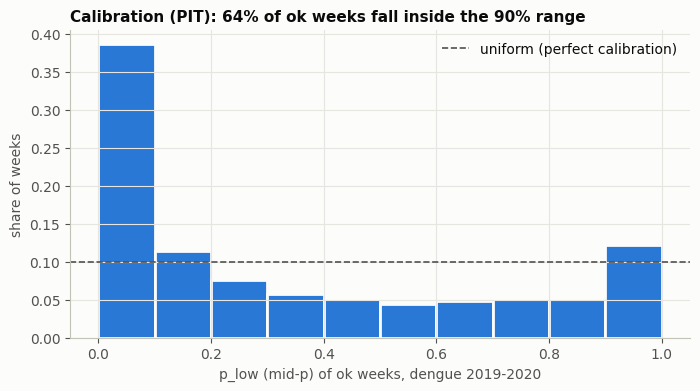

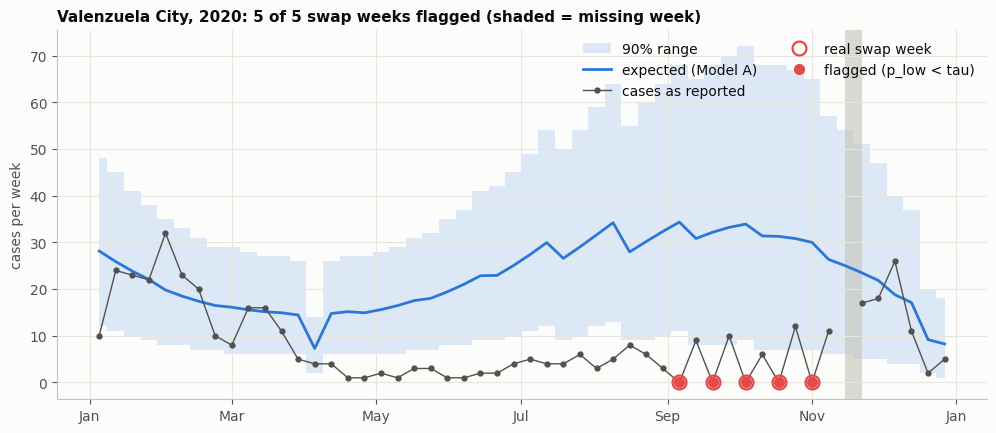

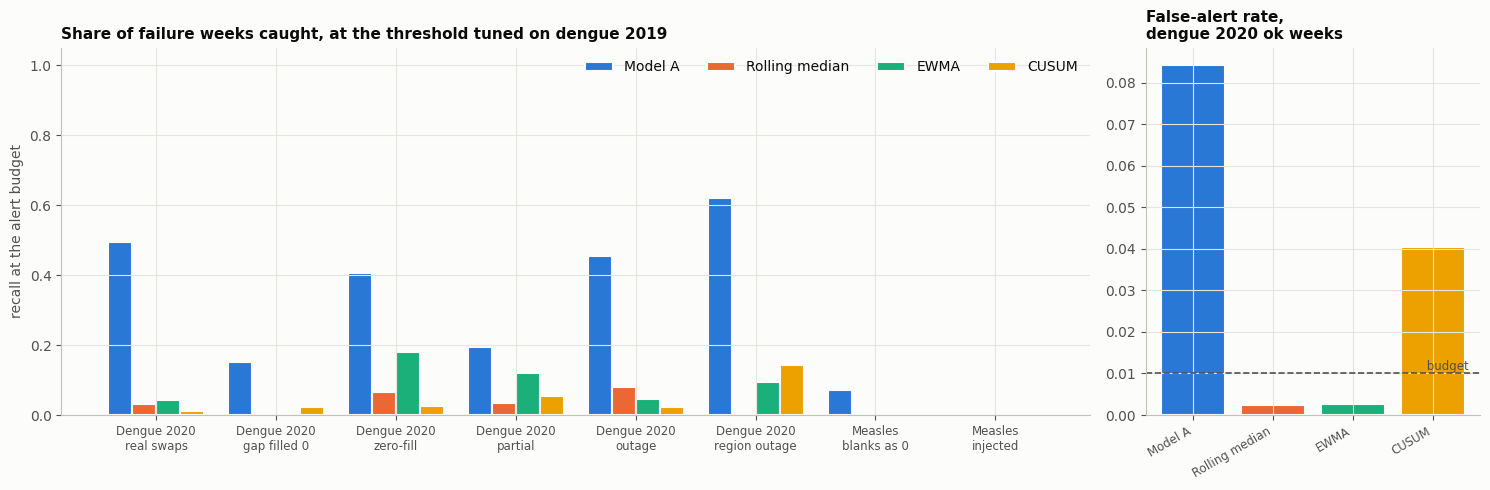

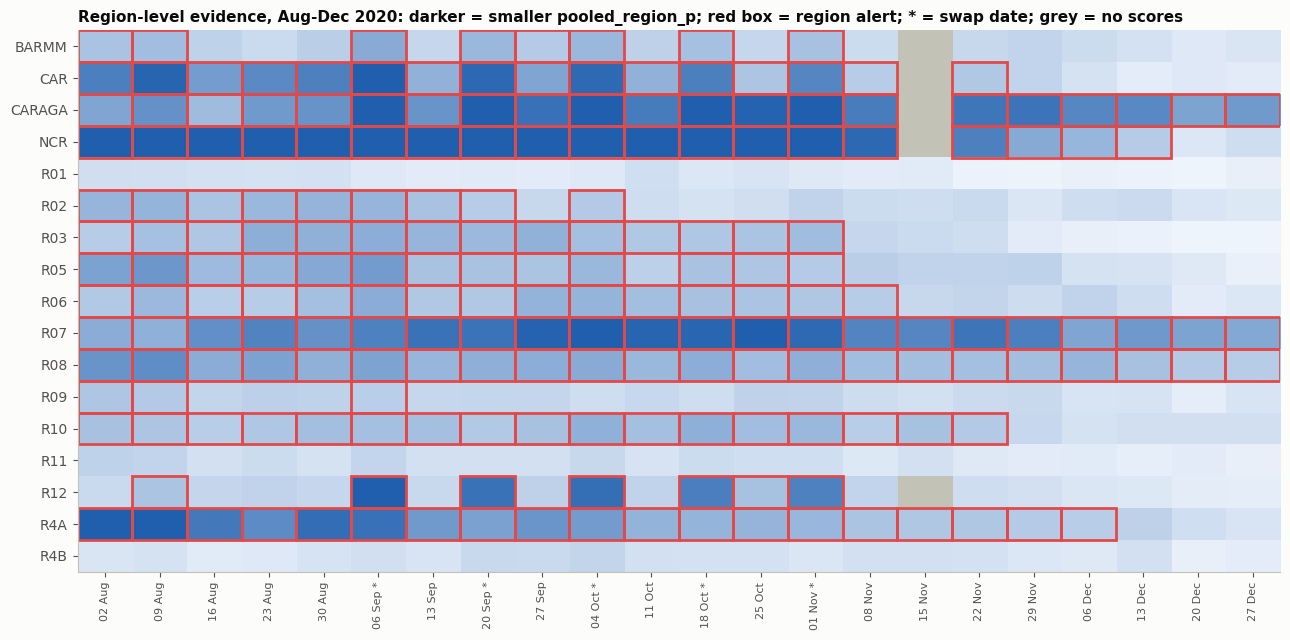

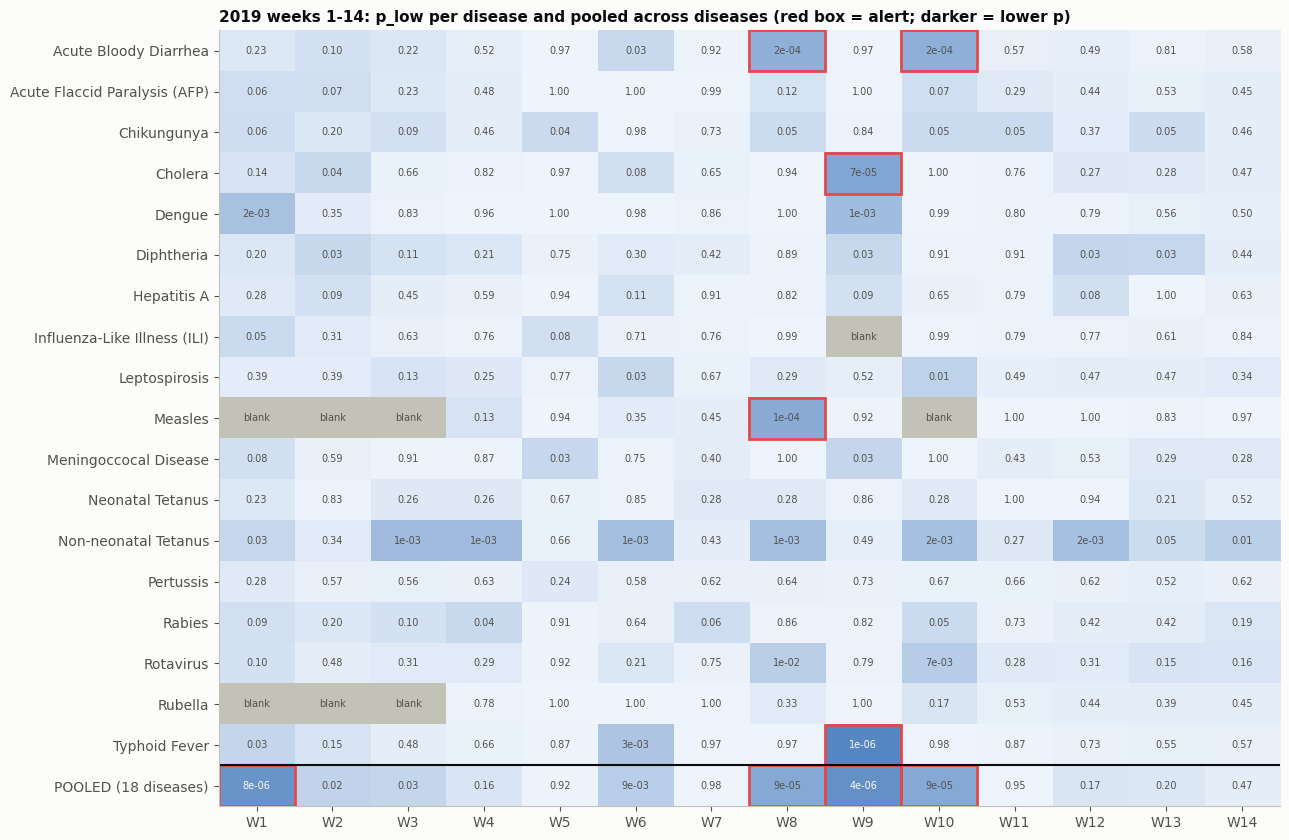

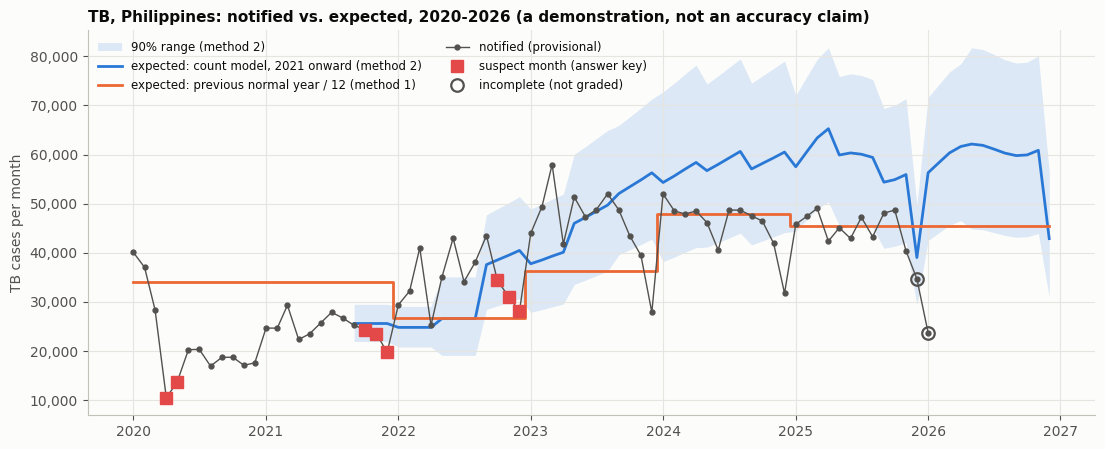

Figures: ['1_pit_histogram.png', '2_valenzuela_2020.png', '3_model_a_vs_baselines.png', '4_region_heat_autumn_2020.png', '5_measles_2019_w1_14_all_diseases.png', '6_tb_notified_vs_expected.png']


In [18]:
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # plain Python: write files only
import matplotlib.dates as mdates
import matplotlib.patches
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib.colors import LinearSegmentedColormap
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
SURF, INK, INK2, GRID, GAP = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#c3c2b7"
MCOL = {"model_a": BLUE, "rolling_median": ORANGE, "ewma": AQUA, "cusum": YELLOW}
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": GAP,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "svg.hashsalt": "model_a",
})
META = {"Software": None}
FIGS = []


def save(fig, name):
    p = FIG_DIR / name
    fig.savefig(p, dpi=150, metadata=META)
    FIGS.append(p)
    plt.show() if "ipykernel" in sys.modules else None
    plt.close(fig)


# 1. PIT histogram
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(np.arange(10) / 10 + 0.05, PIT.share, width=0.1, color=BLUE, edgecolor=SURF, linewidth=2)
ax.axhline(0.1, color=INK2, lw=1.2, ls="--", label="uniform (perfect calibration)")
ax.set_xlabel("p_low (mid-p) of ok weeks, dengue 2019-2020")
ax.set_ylabel("share of weeks")
ax.set_title(f"Calibration (PIT): {COVERAGE90:.0%} of ok weeks fall inside the 90% range")
ax.legend(loc="upper right")
save(fig, "1_pit_histogram.png")

# 2. Valenzuela City 2020
v = lab_d[(lab_d.location == "VALENZUELA CITY") & (lab_d.week_start.dt.year == 2020)]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.fill_between(v.week_start, v.pi_low, v.pi_high, color=BLUE, alpha=0.15, lw=0, step="mid", label="90% range")
ax.plot(v.week_start, v.expected, color=BLUE, lw=2, label="expected (Model A)")
ax.plot(v.week_start, v.cases, "o-", color=INK2, ms=3.5, lw=1, label="cases as reported")
sw = v[fl(v, "swap_cases_deaths")]
fg = sw[sw.p_low < TAU]
ax.plot(sw.week_start, sw.cases, "o", ms=10, mfc="none", mec=RED, mew=1.6, label="real swap week")
ax.plot(fg.week_start, fg.cases, "o", ms=7, color=RED, label="flagged (p_low < tau)")
for w_ in v.loc[v.report_status == "missing", "week_start"]:
    ax.axvspan(w_, w_ + pd.Timedelta(days=7), color=GAP, alpha=0.6, lw=0)
ax.set_ylabel("cases per week")
ax.set_title(f"Valenzuela City, 2020: {len(fg)} of {len(sw)} swap weeks flagged (shaded = missing week)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper right", ncols=2)
save(fig, "2_valenzuela_2020.png")

# 3. Model A vs baselines, dengue test 2020 + transfer sets
sets = [("dengue 2020: real swaps", "Dengue 2020\nreal swaps"),
        ("dengue 2020: regional gap filled with 0", "Dengue 2020\ngap filled 0"),
        ("dengue 2020 (test): injected zero_fill", "Dengue 2020\nzero-fill"),
        ("dengue 2020 (test): injected partial", "Dengue 2020\npartial"),
        ("dengue 2020 (test): injected outage", "Dengue 2020\noutage"),
        ("dengue 2020 (test): injected region_outage", "Dengue 2020\nregion outage"),
        ("measles: blank weeks filled with 0 (careless system)", "Measles\nblanks as 0"),
        ("measles 2017 + 2021: injected, all types", "Measles\ninjected")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [4, 1.3]})
x = np.arange(len(sets))
for j, m in enumerate(METHODS):
    vals = [RESULTS[k].set_index("method").loc[METHOD_LABEL[m], "recall"] for k, _ in sets]
    axes[0].bar(x + (j - 1.5) * 0.2, vals, width=0.2, color=MCOL[m], edgecolor=SURF, linewidth=1.5, label=METHOD_LABEL[m])
axes[0].set_xticks(x, [lbl for _, lbl in sets], fontsize=8.5)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("recall at the alert budget")
axes[0].set_title("Share of failure weeks caught, at the threshold tuned on dengue 2019")
axes[0].legend(loc="upper right", ncols=4)
far = [RESULTS["dengue 2020 (test): injected, all types"].set_index("method").loc[METHOD_LABEL[m], "false_alert_rate"] for m in METHODS]
axes[1].bar(range(4), far, color=[MCOL[m] for m in METHODS], edgecolor=SURF, linewidth=1.5)
axes[1].axhline(B, color=INK2, ls="--", lw=1.2)
axes[1].text(3.45, B, " budget", va="bottom", ha="right", fontsize=8.5, color=INK2)
axes[1].set_xticks(range(4), [METHOD_LABEL[m] for m in METHODS], rotation=30, ha="right", fontsize=8.5)
axes[1].set_title("False-alert rate,\ndengue 2020 ok weeks")
fig.tight_layout()
save(fig, "3_model_a_vs_baselines.png")

# 4. Region heat strip, autumn 2020
h = dengue[(dengue.week_start >= "2020-08-02") & (dengue.week_start <= "2020-12-27")]
grid = h.groupby(["region_id", "week_start"]).pooled_region_p.first().unstack()
grid = grid.reindex(sorted(dengue.region_id.unique()))
val = -np.log10(grid.clip(lower=1e-30))
cmap = LinearSegmentedColormap.from_list("seq", ["#eef4fc", "#1f5fae"])
cmap.set_bad(GAP)
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.imshow(np.ma.masked_invalid(val.to_numpy()), cmap=cmap, vmin=0, vmax=12, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        pv = grid.iat[i, j]
        if pd.notna(pv) and pv < TAU:
            ax.add_patch(matplotlib.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=RED, lw=2))
swap20 = {pd.Timestamp(d_) for d_ in SWAP_EPISODE_DATES if pd.Timestamp(d_).year == 2020}
ax.set_xticks(range(grid.shape[1]), [f"{w_:%d %b}" + (" *" if w_ in swap20 else "") for w_ in grid.columns], rotation=90, fontsize=8)
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
ax.set_title("Region-level evidence, Aug-Dec 2020: darker = smaller pooled_region_p; red box = region alert; * = swap date; grey = no scores")
fig.tight_layout()
save(fig, "4_region_heat_autumn_2020.png")

# 5. Measles 2019 weeks 1-14 across all 18 diseases
e19 = edcs_sc[(edcs_sc.mw_year == 2019) & edcs_sc.mw.between(1, 14)]
tab = e19.pivot(index="disease_raw", columns="mw", values="p_low")
pool = e19.groupby("mw").pooled_disease_p.first()
tab.loc["POOLED (18 diseases)"] = pool
val = -np.log10(tab.clip(lower=1e-30))
fig, ax = plt.subplots(figsize=(13, 8.5))
ax.imshow(np.ma.masked_invalid(val.to_numpy()), cmap=cmap, vmin=0, vmax=8, aspect="auto")
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        pv = tab.iat[i, j]
        ax.text(j, i, "blank" if pd.isna(pv) else f"{pv:.0e}" if pv < 0.01 else f"{pv:.2f}", ha="center", va="center",
                fontsize=7, color=SURF if (pd.notna(pv) and -math.log10(max(pv, 1e-30)) > 4.5) else INK2)
        if pd.notna(pv) and pv < TAU:
            ax.add_patch(matplotlib.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=RED, lw=2))
ax.axhline(tab.shape[0] - 1.5, color=INK, lw=1.5)
ax.set_xticks(range(tab.shape[1]), [f"W{c}" for c in tab.columns])
ax.set_yticks(range(tab.shape[0]), tab.index)
ax.grid(False)
ax.set_title("2019 weeks 1-14: p_low per disease and pooled across diseases (red box = alert; darker = lower p)")
fig.tight_layout()
save(fig, "5_measles_2019_w1_14_all_diseases.png")

# 6. TB notified vs expected
fig, ax = plt.subplots(figsize=(13, 5))
mm2 = m2.assign(month_start=tb.month_start)
ax.fill_between(tb.month_start, m2.pi_low, m2.pi_high, color=BLUE, alpha=0.15, lw=0, label="90% range (method 2)")
ax.plot(tb.month_start, m2.expected, color=BLUE, lw=2, label="expected: count model, 2021 onward (method 2)")
ax.plot(tb.month_start, m1.expected, color=ORANGE, lw=2, drawstyle="steps-mid", label="expected: previous normal year / 12 (method 1)")
ax.plot(tb.month_start, tb.cases, "o-", color=INK2, ms=3.5, lw=1, label="notified (provisional)")
su = TBEVAL[TBEVAL.qa_label.eq("suspect")]
ax.plot(su.month_start, su.cases, "s", ms=8, color=RED, label="suspect month (answer key)")
inc = TBEVAL[TBEVAL.qa_label.eq("incomplete")]
ax.plot(inc.month_start, inc.cases, "o", ms=9, mfc="none", mec=INK2, mew=1.6, label="incomplete (not graded)")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v_, _: f"{v_:,.0f}"))
ax.set_ylabel("TB cases per month")
ax.set_title("TB, Philippines: notified vs. expected, 2020-2026 (a demonstration, not an accuracy claim)")
ax.legend(loc="upper left", ncols=2, fontsize=8.5)
save(fig, "6_tb_notified_vs_expected.png")
print("Figures:", [p.name for p in FIGS])

## 10. Summary
For each failure set and method: **recall** (share of failure weeks caught at the frozen threshold), the
**false-alert rate** on that set's `ok` weeks (the budget is 0.01), **F1**, and **AUC**, a threshold-free measure of
how well the scores rank failure weeks above `ok` weeks (0.5 = no better than chance). Recall only means something
next to the false-alert rate. Event detection, weeks to detect and precision are in `eval_report.md`.

In [19]:
SUMMARY_SETS = [
    ("Dengue", "2020 test: real swaps", "dengue 2020: real swaps"),
    ("Dengue", "2020 test: regional gap filled with 0", "dengue 2020: regional gap filled with 0"),
    ("Dengue", "2020 test: injected (all types)", "dengue 2020 (test): injected, all types"),
    ("Dengue", "2017 episode, 2016-only history", "dengue 2017 episode, 2016-only model: swaps + gap"),
    ("Measles", "2019 W8 group zero (real)", "measles: 2019 W8 group zero (real)"),
    ("Measles", "blank weeks filled with 0", "measles: blank weeks filled with 0 (careless system)"),
    ("Measles", "2017 + 2021 injected", "measles 2017 + 2021: injected, all types"),
    ("Rubella", "2019 W8 group zero (real)", "rubella: 2019 W8 group zero (real)"),
    ("TB", "8 suspect months, method 1", "TB: 8 suspect months, Model A method 1 (previous year / 12)"),
    ("TB", "8 suspect months, method 2", "TB: 8 suspect months, Model A method 2 (count model, 2021 onward)"),
]
srows = []
for dis, nm, key in SUMMARY_SETS:
    r = RESULTS[key].set_index("method")
    for metric in ("recall", "false_alert_rate", "f1", "auc"):
        srows.append({"disease": dis, "failure set": nm, "positives": int(r.positives.iloc[0]), "metric": metric,
                      **{METHOD_LABEL[m]: r.loc[METHOD_LABEL[m], metric] for m in METHODS}})
SUMMARY = pd.DataFrame(srows)
display(SUMMARY.round(3))

# Every place a baseline does better than Model A (lower is better only for the false-alert rate).
LOSSES = []
for _, r in SUMMARY.iterrows():
    for b in (METHOD_LABEL[x] for x in BASELINES):
        a_, b_ = r["Model A"], r[b]
        if pd.isna(a_) or pd.isna(b_):
            continue
        worse = (b_ < a_ - 1e-12) if r.metric == "false_alert_rate" else (b_ > a_ + 1e-12)
        if worse:
            LOSSES.append({"disease": r.disease, "failure set": r["failure set"], "metric": r.metric,
                           "baseline": b, "baseline value": b_, "Model A": a_})
LOSSES = pd.DataFrame(LOSSES, columns=["disease", "failure set", "metric", "baseline", "baseline value", "Model A"])
print(f"A baseline beats Model A in {len(LOSSES)} (set, metric, baseline) comparisons:")
display(LOSSES.round(4))

,disease,failure set,positives,metric,Model A,Rolling median,EWMA,CUSUM
0,Dengue,2020 test: real swaps,158,recall,0.494,0.032,0.044,0.013
1,Dengue,2020 test: real swaps,158,false_alert_rate,0.121,0.004,0.006,0.038
2,Dengue,2020 test: real swaps,158,f1,0.156,0.053,0.069,0.010
3,Dengue,2020 test: real swaps,158,auc,0.842,0.700,0.800,0.381
4,Dengue,2020 test: regional gap filled with 0,46,recall,0.152,0.000,0.000,0.022
5,Dengue,2020 test: regional gap filled with 0,46,false_alert_rate,0.084,0.003,0.003,0.040
6,Dengue,2020 test: regional gap filled with 0,46,f1,0.025,0.000,0.000,0.007
7,Dengue,2020 test: regional gap filled with 0,46,auc,0.732,0.574,0.731,0.260
8,Dengue,2020 test: injected (all types),407,recall,0.349,0.054,0.125,0.042
9,Dengue,2020 test: injected (all types),407,false_alert_rate,0.084,0.003,0.003,0.040


A baseline beats Model A in 35 (set, metric, baseline) comparisons:


,disease,failure set,metric,baseline,baseline value,Model A
0,Dengue,2020 test: real swaps,false_alert_rate,Rolling median,0.0039,0.1207
1,Dengue,2020 test: real swaps,false_alert_rate,EWMA,0.0060,0.1207
2,Dengue,2020 test: real swaps,false_alert_rate,CUSUM,0.0381,0.1207
3,Dengue,2020 test: regional gap filled with 0,false_alert_rate,Rolling median,0.0025,0.0842
4,Dengue,2020 test: regional gap filled with 0,false_alert_rate,EWMA,0.0027,0.0842
5,Dengue,2020 test: regional gap filled with 0,false_alert_rate,CUSUM,0.0404,0.0842
6,Dengue,2020 test: injected (all types),false_alert_rate,Rolling median,0.0025,0.0842
7,Dengue,2020 test: injected (all types),false_alert_rate,EWMA,0.0027,0.0842
8,Dengue,2020 test: injected (all types),false_alert_rate,CUSUM,0.0404,0.0842
9,Dengue,2020 test: injected (all types),auc,Rolling median,0.8595,0.7689


### Conclusion
Written from the numbers above, so it can't drift from the results.

In [20]:
def R(key, method="Model A", metric="recall"):
    return float(RESULTS[key].set_index("method").loc[method, metric])


BL = [METHOD_LABEL[b] for b in BASELINES]
k_sw, k_inj, k_ep = "dengue 2020: real swaps", "dengue 2020 (test): injected, all types", "dengue 2017 episode, 2016-only model: swaps + gap"
far_a_all = [R(k, metric="false_alert_rate") for k in (k_sw, k_inj)]  # the two 2020 runs have different ok pools
far_a = min(far_a_all)
far_b_all = [R(k, b, "false_alert_rate") for k in (k_sw, k_inj) for b in BL]
auc_rows = SUMMARY[SUMMARY.metric == "auc"]
auc_best = [r["disease"] + " " + r["failure set"] for _, r in auc_rows.iterrows() if r["Model A"] >= max(r[b] for b in BL)]
auc_lose = [r["disease"] + " " + r["failure set"] for _, r in auc_rows.iterrows() if r["Model A"] < max(r[b] for b in BL)]
best_auc_b = max(BL, key=lambda b: R(k_sw, b, "auc"))
cov_pre = CAL_BY_YEAR[CAL_BY_YEAR.year.between(2017, 2019)]["inside 90% range"]
rc = ROOT_CAUSE.set_index("failure set")
m_p = float(W8.loc[W8.disease == "measles", "p_low"].iloc[0])
pool_word = ("far stronger than" if W8_POOLED < m_p / 100 else "stronger than" if W8_POOLED < m_p / 3
             else "only slightly stronger than" if W8_POOLED < m_p else "not stronger than")
tb1 = "TB: 8 suspect months, Model A method 1 (previous year / 12)"
tb2 = "TB: 8 suspect months, Model A method 2 (count model, 2021 onward)"
c = []
c.append(f"- **Alert budget.** The threshold holds the budget on dengue 2019 ({far_tune['model_a']:.1%}) by construction. "
         f"In the 2020 test year Model A raises false alerts on **{min(far_a_all):.1%}–{max(far_a_all):.1%}** of ok "
         "location-weeks"
         + (f", **{far_a / B:.0f}–{max(far_a_all) / B:.0f}× the budget**: dengue fell below its seasonal pattern during "
            "COVID-19, and a model of trend + season + holidays cannot follow that level shift." if far_a > 2 * B
            else ", within reach of the budget.")
         + f" The baselines, which track the recent level, stay at {min(far_b_all):.1%}–{max(far_b_all):.1%}.")
c.append(f"- **Detection.** On the 581 real swaps, Model A catches {R(k_sw):.0%} of the 2020 swap weeks "
         f"(baselines {min(R(k_sw, b) for b in BL):.0%}–{max(R(k_sw, b) for b in BL):.0%}), and {R(k_ep):.0%} of the 2017 "
         f"episode with only 2016 as history, at a {R(k_ep, metric='false_alert_rate'):.1%} false-alert rate. Threshold-free, "
         f"its AUC on the 2020 swaps is {R(k_sw, metric='auc'):.2f} against {R(k_sw, best_auc_b, 'auc'):.2f} for the best "
         f"baseline ({best_auc_b}); on 2020 injected failures {R(k_inj, metric='auc'):.2f} against "
         f"{max(R(k_inj, b, 'auc') for b in BL):.2f}.")
c.append(f"- **Calibration.** Even before the test year, only {cov_pre.min():.0%}–{cov_pre.max():.0%} of ok weeks fall "
         "inside the 90% range (2017–2019): the range is too narrow (parameter uncertainty and year-to-year epidemic size "
         "are not modelled), so small p-values are more common than they should be.")
c.append(f"- **Root cause.** Region-level pooling flags {rc.loc['real swaps 2017', 'region flagged (pooled_region_p < tau)']:.0%} "
         f"of the 2017 swap region-weeks with {rc.loc['real swaps 2017', 'region false-alert rate (clean region-weeks)']:.0%} "
         f"false region alerts; in 2020 it flags {rc.loc['real swaps 2020 (test)', 'region flagged (pooled_region_p < tau)']:.0%} "
         f"but with {rc.loc['real swaps 2020 (test)', 'region false-alert rate (clean region-weeks)']:.0%} false region alerts, "
         "so in 2020 the region signal does not separate the swap from the COVID-era drop.")
c.append(f"- **Measles (no retuning).** The 2019 week 8 zero is flagged by measles alone (p_low {m_p:.2g}); pooling the "
         f"18 diseases gives {W8_POOLED:.2g}, {pool_word} measles alone. Rubella's zero that week is unremarkable for "
         f"rubella. Blank weeks filled with 0: {R('measles: blank weeks filled with 0 (careless system)'):.0%} caught; "
         f"injected failures in the quiet years: {R('measles 2017 + 2021: injected, all types'):.0%}. Sparse series leave "
         "little room to tell a false zero from a real one.")
c.append(f"- **TB (a demonstration).** Method 1 (previous year ÷ 12) flags {R(tb1):.0%} of the 8 suspect months "
         f"(April–May 2020) with {R(tb1, metric='false_alert_rate'):.0%} false alerts; method 2 (count model from 2021) "
         f"flags {R(tb2):.0%}, at {R(tb2, metric='false_alert_rate'):.1%}. DOH's partial months (Oct–Dec 2021, 2022) run "
         "at 78–98% of the year's earlier median (TB README), too small a shortfall to cross a threshold set for 1 "
         "false alert per 100.")
n_by = LOSSES.metric.value_counts()
rec_rows = SUMMARY[SUMMARY.metric == "recall"]
rec_best = int(sum(r["Model A"] > max(r[b] for b in BL) for _, r in rec_rows.iterrows()))
c.append(f"- **Where baselines win.** {len(LOSSES)} comparisons (listed above): "
         + ", ".join(f"{int(v)} on {k.replace('_', ' ')}" for k, v in n_by.items()) + ". "
         + f"Ranking failures threshold-free (AUC), Model A is best on {len(auc_best)} of {len(auc_rows)} sets"
         + (f" ({'; '.join(auc_best)})" if auc_best else "")
         + (f", and a baseline ranks better on {'; '.join(auc_lose)}" if auc_lose else "")
         + f". At the frozen thresholds Model A has strictly the highest recall on {rec_best} of {len(rec_rows)} sets, "
         "but on dengue 2020 it pays for that with far more false alerts.")
c.append("- **Limits.** Labels for measles and TB are few and partly found by inspection; Fisher pooling assumes "
         "independence and is dominated by its smallest p-value; injected failures are simulated; TB method 1 borrows "
         "its dispersion from later months. Results are leads for surveillance staff to verify, not confirmed errors.")
CONCLUSION = "\n".join(c)
display(Markdown(CONCLUSION))

- **Alert budget.** The threshold holds the budget on dengue 2019 (1.0%) by construction. In the 2020 test year Model A raises false alerts on **8.4%–12.1%** of ok location-weeks, **8–12× the budget**: dengue fell below its seasonal pattern during COVID-19, and a model of trend + season + holidays cannot follow that level shift. The baselines, which track the recent level, stay at 0.3%–4.0%.
- **Detection.** On the 581 real swaps, Model A catches 49% of the 2020 swap weeks (baselines 1%–4%), and 47% of the 2017 episode with only 2016 as history, at a 4.3% false-alert rate. Threshold-free, its AUC on the 2020 swaps is 0.84 against 0.80 for the best baseline (EWMA); on 2020 injected failures 0.77 against 0.89.
- **Calibration.** Even before the test year, only 73%–79% of ok weeks fall inside the 90% range (2017–2019): the range is too narrow (parameter uncertainty and year-to-year epidemic size are not modelled), so small p-values are more common than they should be.
- **Root cause.** Region-level pooling flags 100% of the 2017 swap region-weeks with 5% false region alerts; in 2020 it flags 100% but with 62% false region alerts, so in 2020 the region signal does not separate the swap from the COVID-era drop.
- **Measles (no retuning).** The 2019 week 8 zero is flagged by measles alone (p_low 0.00013); pooling the 18 diseases gives 9.1e-05, only slightly stronger than measles alone. Rubella's zero that week is unremarkable for rubella. Blank weeks filled with 0: 7% caught; injected failures in the quiet years: 0%. Sparse series leave little room to tell a false zero from a real one.
- **TB (a demonstration).** Method 1 (previous year ÷ 12) flags 25% of the 8 suspect months (April–May 2020) with 0% false alerts; method 2 (count model from 2021) flags 0%, at 4.4%. DOH's partial months (Oct–Dec 2021, 2022) run at 78–98% of the year's earlier median (TB README), too small a shortfall to cross a threshold set for 1 false alert per 100.
- **Where baselines win.** 35 comparisons (listed above): 23 on false alert rate, 10 on auc, 1 on recall, 1 on f1. Ranking failures threshold-free (AUC), Model A is best on 5 of 10 sets (Dengue 2020 test: real swaps; Dengue 2020 test: regional gap filled with 0; Dengue 2017 episode, 2016-only history; Measles 2019 W8 group zero (real); Measles blank weeks filled with 0), and a baseline ranks better on Dengue 2020 test: injected (all types); Measles 2017 + 2021 injected; Rubella 2019 W8 group zero (real); TB 8 suspect months, method 1; TB 8 suspect months, method 2. At the frozen thresholds Model A has strictly the highest recall on 7 of 10 sets, but on dengue 2020 it pays for that with far more false alerts.
- **Limits.** Labels for measles and TB are few and partly found by inspection; Fisher pooling assumes independence and is dominated by its smallest p-value; injected failures are simulated; TB method 1 borrows its dispersion from later months. Results are leads for surveillance staff to verify, not confirmed errors.

In [21]:
def md(df, floats=3):
    cols = list(df.columns)
    def f(v):
        if isinstance(v, (float, np.floating)):
            return "" if np.isnan(v) else (f"{v:.{floats}g}" if abs(v) < 1e-3 and v != 0 else f"{v:.{floats}f}")
        return str(v)
    return "\n".join(["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
                     + ["| " + " | ".join(f(v) for v in row) + " |" for row in df.itertuples(index=False)])


RUNTIME = time.time() - T0
cfg_out = dict(CONFIG)
cfg_out.update({
    "TAU_model_a": TAU, "BASELINE_THRESHOLDS": H, "tuning_rows_dengue_2019": tune_rows,
    "false_alert_rate_at_tuning": far_tune, "TB_alpha_method1": alpha_m1,
    "inputs_sha256": {p: hashlib.sha256((DATA_DIR / p).read_bytes()).hexdigest() for p in [
        "dengue/clean/dengue_province_weekly.csv", "shared/edcs_national_weekly.csv", "measles/clean/measles_national_weekly.csv",
        "tb/clean/tb_national_monthly.csv", "tb/clean/tb_national_annual.csv", "shared/calendar_weeks.csv", "shared/locations.csv"]},
    "scores_sha256": hashlib.sha256((OUT_DIR / "scores.csv").read_bytes()).hexdigest(),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scipy": scipy.__version__, "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__},
    "runtime_seconds": round(RUNTIME, 1), "colab": IN_COLAB,
})
(OUT_DIR / "config.json").write_text(json.dumps(cfg_out, indent=2, default=str), encoding="utf-8")

fb = fallbacks.groupby(["run", "level"]).size().rename("refits").reset_index()
L = ["# Model A: evaluation report", "",
     f"Generated by `notebooks/model_a.ipynb` ({CONFIG['MODEL_VERSION']}). Runtime {RUNTIME / 60:.1f} min. "
     f"scores.csv SHA-256 `{cfg_out['scores_sha256']}`.", "",
     "## Threshold (tuned once, on dengue 2019 ok location-weeks)", "",
     md(pd.DataFrame({"method": [METHOD_LABEL[m] for m in METHODS],
                      "threshold": [f"p_low < {TAU:.4g}"] + [f"score > {H[b]:.4g}" for b in BASELINES],
                      "false-alert rate 2019": [far_tune[m] for m in METHODS]}), 4),
     "", f"Tuning rows: {tune_rows:,}. Alert budget: {B:.0%} of location-weeks.", "",
     "## Conclusion", "", CONCLUSION, "",
     "## Summary (frozen thresholds; AUC is threshold-free)", "", md(SUMMARY), "",
     f"## Where a baseline beats Model A ({len(LOSSES)} comparisons)", "",
     md(LOSSES, 4) if len(LOSSES) else "Nowhere.", "",
     "## Every failure set", ""]
for k, v_ in RESULTS.items():
    L += [f"### {k}", "", md(v_), ""]
L += ["## Root cause: region-level alerts (dengue)", "", md(ROOT_CAUSE), "",
      "## Calibration", "", f"Share of ok weeks (dengue 2019-2020) inside the 90% range: {COVERAGE90:.3f}.", "",
      md(PIT), "", "By year (ok weeks):", "", md(CAL_BY_YEAR), "",
      "## Measles 2019 week 8 (group zero)", "", md(W8[W8.disease.isin(["measles", "rubella"])]), "",
      f"pooled_disease_p (Fisher over {int(w8.p_low.notna().sum())} diseases): {W8_POOLED:.3g}; tau = {TAU:.3g}.", "",
      "## TB suspect months", "", md(TB_TABLE[TB_TABLE.qa_label.eq('suspect')]), "",
      f"Method 1 dispersion alpha = {alpha_m1:.4g}, estimated from months 2021 onward (a look-ahead; demonstration only).", "",
      "## Fallbacks (refits not at the full model)", "", md(fb), "",
      "## Injected failures", "",
      md(inj_all.groupby(["disease", "scenario"]).agg(events=("event_id", "nunique"), rows=("event_id", "size")).reset_index()), "",
      "Saved to `data/synthetic/model_a_injected_failures.csv`.", "",
      "## Figures", ""] + [f"- `figures/{p.name}`" for p in FIGS] + [""]
(OUT_DIR / "eval_report.md").write_text("\n".join(L), encoding="utf-8")
print(f"Done in {RUNTIME / 60:.1f} min. Wrote scores.csv, config.json, eval_report.md, fallback_log.csv, {len(FIGS)} figures.")

Done in 9.3 min. Wrote scores.csv, config.json, eval_report.md, fallback_log.csv, 6 figures.


### Next steps (not done here, so the test stays untouched)
- Give the count model a sense of the **recent level** (for example the mean of the last 4 reported weeks as a
  covariate, as in endemic–epidemic models), or use the `covid_period` calendar flag, so a real level shift isn't
  read as a reporting failure. Choose it on 2016–2019 only, then re-test on 2020 once.
- Widen the predictive range for parameter uncertainty and year-to-year epidemic size (the PIT shows it's too narrow).
- Try a pooling method that tolerates dependence (for example Stouffer with an estimated correlation).
- Tune the threshold on 2019 with injected failures included, so the budget trades off against detection.